# E107 · What a hidden confounder can do: sensitivity analysis on the job-training benchmark

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the **National Supported Work** (NSW) experiment in the Dehejia & Wahba (1999) subset of LaLonde (1986): 185 randomly assigned trainees and 260 randomised controls, with 1974, 1975 and 1978 earnings; and LaLonde's **CPS** comparison sample of 15,992 men with the same variables. Both come from the `causaldata` R package (MIT licence) via Rdatasets. Simulated: only the synthetic confounders planted in part C, which are built on the real rows; every other number is computed from the real data |
| **You will learn** | Why an observational estimate depends on what was measured, shown against a randomised answer key · **hiding a measured confounder** and a test sample whose true effect is zero · **omitted-variable bias** in the partial-$R^2$ form, checked to the dollar by **planting** confounders of chosen strength on real rows · why balance checks cannot see them · the **robustness value**, contour plots, **benchmarking** and its two traps (Cinelli & Hazlett 2020) · **E-values** for a binary outcome (VanderWeele & Ding 2017) · **Rosenbaum bounds** for matched pairs and amplification · Bayesian sensitivity models in PyMC whose sensitivity parameters the data never learn, priors from benchmarks, and a latent-class model that learns them for the wrong reason · **placebo outcomes** and within-study comparisons · how to write the result for someone who has to act on it |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy import optimize, special, stats

from pymc_challenges import data

RANDOM_SEED = 107
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

Every observational estimate rests on a sentence that cannot be tested from the data: *given what
we measured, who got the treatment is as good as random*. Anyone defending such an estimate soon
hears "what if there is something you did not measure?" The honest answer is neither "we
controlled for everything" nor "then nothing can be known". It is a number: how strong a hidden
confounder would have to be, compared with things we did measure, to change the decision.

The data are the most famous test bed in the field. In the mid 1970s the National Supported Work
demonstration gave a year of subsidised work experience to disadvantaged workers, and assigned
applicants **at random**. LaLonde (1986) took the treated men, threw away the randomised controls,
and replaced them with men from the Current Population Survey (CPS), as an analyst without an
experiment would, and found that the econometric methods of the day often got even the sign of the
experimental answer wrong. Dehejia & Wahba (1999) showed that on a subset with two years of
pre-programme earnings, propensity-score methods came close; Smith & Todd (2005) showed how much
that depended on the sample and the specification. Here we keep the data and change the question:
rather than "can we get the right answer", we ask **what an unmeasured confounder could do to
whatever answer we get, and how to show it**.

That question has a literature of its own. The modern form of omitted-variable bias for
regression, written in **partial $R^2$**, comes from Cinelli & Hazlett (2020), who added the
robustness value and benchmarking against observed covariates. VanderWeele & Ding (2017) gave
the **E-value** for risk ratios. Rosenbaum (2002) bounded the p-value of a matched study when
treatment odds within pairs differ by a factor $\Gamma$, and Rosenbaum & Silber (2009) split
$\Gamma$ into a confounder's effect on treatment and on outcome. Bayesian versions put a prior on
the confounder's strength (McCandless, Gustafson & Levy 2007; Gustafson 2015 on partial
identification). Here we use them all on
a problem where the truth is known, so we can see when each one is right and when it misleads.

| part | question | tool |
|---|---|---|
| A | What is the answer key? | the randomised NSW experiment |
| B | What does an unmeasured confounder do to a real estimate? | a ladder of covariate sets on NSW trainees against the CPS; hiding the earnings history; a test sample whose true effect is zero |
| C | Can we build a confounder of known strength? | the omitted-variable-bias formula in partial $R^2$; synthetic confounders planted on the real rows; balance checks that cannot see them |
| D | How strong would it have to be? | robustness value, contour plots, extreme scenarios and benchmarks, with their two traps |
| E | Other yardsticks | E-values for employment; Rosenbaum bounds for matched pairs, calibrated on the experiment |
| F | Beliefs about the confounder as priors | three PyMC sensitivity models: one the data cannot touch, one with benchmark priors, one that learns too much |
| G | Evidence that can narrow it | a placebo outcome that fails for a good reason; the within-study comparison |
| H | Saying it | a tipping-point sentence and a sensitivity table for stakeholders |

## A · The answer key

The NSW file holds the Dehejia-Wahba subset of LaLonde's men, chosen by the month of random
assignment and, for some of them, by their earnings before it; Smith & Todd (2005) point out that
a rule of that kind conditions on pre-programme earnings. LaLonde kept only men who entered the
programme from January 1976 (Imbens & Xu 2024), so 1975 lies before it. Each row has age, years
of schooling, indicators for black, Hispanic, married and no high-school degree, real earnings in
1974, 1975 and 1978, and the randomised treatment. For the NSW men the "1974" earnings are, as
Smith & Todd note, earnings in months 13-24 before random assignment, so they line up with the
CPS men's calendar 1974 only roughly. The CPS file has the same columns for 15,992 men drawn from
the 1976 survey. We add indicators for zero earnings in 1974 and 1975, which matter because most
trainees earned nothing, and an indicator for any earnings in 1978, our binary outcome for part E.

In [2]:
data.describe("nsw")
nsw = data.load("nsw")
data.describe("cps")
cps = data.load("cps")
for d_ in (nsw, cps):
    d_["u74"] = (d_.re74 == 0).astype(float)
    d_["u75"] = (d_.re75 == 0).astype(float)
    d_["emp78"] = (d_.re78 > 0).astype(float)
print(f"NSW: {nsw.data_id.unique()[0]}, {int(nsw.treat.sum())} treated, {int((nsw.treat == 0).sum())} controls; "
      f"CPS: {cps.data_id.unique()[0]}, {len(cps):,} men")
COLS = ["age", "educ", "black", "hisp", "marr", "nodegree", "u74", "u75", "re74", "re75", "re78"]
means = pd.DataFrame({"NSW treated": nsw[nsw.treat == 1][COLS].mean(), "NSW controls": nsw[nsw.treat == 0][COLS].mean(),
                      "CPS": cps[COLS].mean()})
print(means.round(2).to_string())

nsw: Randomised job-training experiment: 185 treated, 260 controls, earnings in 1978.
  source: LaLonde (1986) / Dehejia & Wahba (1999), National Supported Work experiment.
  url:    https://vincentarelbundock.github.io/Rdatasets/csv/causaldata/nsw_mixtape.csv
cps: 15,992 non-experimental 'controls' with the same covariates as `nsw`.
  source: Current Population Survey comparison sample used by LaLonde (1986).
  url:    https://vincentarelbundock.github.io/Rdatasets/csv/causaldata/cps_mixtape.csv
NSW: Dehejia-Wahba Sample, 185 treated, 260 controls; CPS: CPS1, 15,992 men
          NSW treated  NSW controls       CPS
age             25.82         25.05     33.23
educ            10.35         10.09     12.03
black            0.84          0.83      0.07
hisp             0.06          0.11      0.07
marr             0.19          0.15      0.71
nodegree         0.71          0.83      0.30
u74              0.71          0.75      0.12
u75              0.60          0.68      0.11
re74    

Randomisation did its job: trainees and randomised controls are alike on every column, earning
about \$2,100 in 1974 and \$1,300-1,500 in 1975, and three quarters of each earned nothing in
1974.
The CPS men are another population. They are older (33 against 26), mostly white (7% black
against 84%), mostly married (71% against 19%), and earned about \$14,000 a year before the
programme against the trainees' \$2,000. Any comparison of trainees with the CPS is a comparison
of very different men, and everything below is about how much adjustment can bridge that gap.

The experimental effect on 1978 earnings is a difference in means. We give its
heteroskedasticity-robust standard error and the same difference adjusted for covariates,
which should barely move it.

In [3]:
DEMO = ["age", "educ", "black", "hisp", "marr", "nodegree"]
EARN = ["re74", "re75", "u74", "u75"]


def design(df, spec):
    """Covariate matrix for a named specification (no intercept, no treatment column)."""
    cols = {}
    if spec != "none":
        for c in DEMO:
            cols[c] = df[c].to_numpy(float)
    if spec in ("demo+re74", "demo+earn", "flex"):
        cols["re74"], cols["u74"] = df.re74.to_numpy(float), df.u74.to_numpy(float)
    if spec in ("demo+re75", "demo+earn", "flex"):
        cols["re75"], cols["u75"] = df.re75.to_numpy(float), df.u75.to_numpy(float)
    if spec in ("flex", "flex-noearn"):
        a, e = df.age.to_numpy(float), df.educ.to_numpy(float)
        cols["age2"], cols["age3"], cols["educ2"] = a ** 2 / 100, a ** 3 / 1e4, e ** 2 / 10
    if spec == "flex":
        r74, r75 = df.re74.to_numpy(float), df.re75.to_numpy(float)
        cols["educ_re74"], cols["re74sq"], cols["re75sq"] = df.educ.to_numpy(float) * r74 / 10, r74 ** 2 / 1e5, r75 ** 2 / 1e5
    if not cols:
        return np.zeros((len(df), 0)), []
    return np.column_stack(list(cols.values())), list(cols)


def ols(y, X, hc=False):
    """Least squares of y on [1, X]: coefficients, standard errors (classical or HC1), residual df, residuals."""
    Z = np.column_stack([np.ones(len(y)), X])
    q, r = np.linalg.qr(Z)
    b = np.linalg.solve(r, q.T @ y)
    res = y - Z @ b
    dof = Z.shape[0] - Z.shape[1]
    rinv = np.linalg.inv(r)
    xtx_inv = rinv @ rinv.T
    if hc:
        V = xtx_inv @ ((Z * res[:, None] ** 2).T @ Z) @ xtx_inv * Z.shape[0] / dof
    else:
        V = xtx_inv * (res @ res / dof)
    return b, np.sqrt(np.diag(V)), dof, res


def treat_ols(y, d, X, hc=False):
    """Coefficient of the treatment d in a regression of y on d and X."""
    b, se, dof, _ = ols(y, np.column_stack([d, X]), hc=hc)
    return b[1], se[1], dof


y_e, d_e = nsw.re78.to_numpy(float), nsw.treat.to_numpy(float)
for spec in ("none", "demo", "demo+earn"):
    e, s, _ = treat_ols(y_e, d_e, design(nsw, spec)[0], hc=True)
    print(f"experiment, covariates {spec:9s}: {e:6,.0f}  (robust se {s:4.0f})")
EXP, EXP_SE = treat_ols(y_e, d_e, design(nsw, "none")[0], hc=True)[:2]
p1_e, p0_e = nsw.emp78[nsw.treat == 1].mean(), nsw.emp78[nsw.treat == 0].mean()
EXP_LOR = special.logit(p1_e) - special.logit(p0_e)
print(f"employed in 1978: trainees {p1_e:.1%}, controls {p0_e:.1%}; risk ratio {p1_e / p0_e:.2f}, log odds ratio {EXP_LOR:.2f}")

experiment, covariates none     :  1,794  (robust se  671)
experiment, covariates demo     :  1,671  (robust se  673)
experiment, covariates demo+earn:  1,671  (robust se  680)
employed in 1978: trainees 75.7%, controls 64.6%; risk ratio 1.17, log odds ratio 0.53


The programme raised 1978 earnings by about **\$1,794** (robust se \$671), and adjusting for the
covariates moves it to \$1,671, well within noise. Three quarters of trainees had some earnings
in 1978 against 65% of controls, a risk ratio of 1.17. These are the answer key. Everything that
follows pretends, as LaLonde did, that the randomised controls do not exist, except where we
bring them back on purpose to measure bias directly.

## B · What an unmeasured confounder does to a real estimate

### B1 · A ladder of covariate sets

Put the 185 trainees next to the 15,992 CPS men and estimate the effect on the trainees (the ATT)
three ways for each covariate set: a regression with a treatment dummy, inverse-probability
weighting with odds weights $e(x)/(1-e(x))$ on the comparison men, and one-to-one
nearest-neighbour matching (with replacement) on the logit of a propensity score $e(x)$ fitted by
logistic regression. The sets climb from nothing to demographics, to demographics plus one or both
years of earnings, to a flexible specification with a cubic in age, squared schooling and
earnings, and schooling times 1974 earnings, close to Dehejia & Wahba's. One step is the flexible
set with the earnings terms removed. Strictly, the regression coefficient is not the effect on the
treated: when effects vary it is a variance-weighted average, close to the ATT only if the effect
is roughly constant. The omitted-variable algebra of parts C and D applies to that coefficient.

In [4]:
def logit_newton(y, Z, ridge=1e-6):
    """Maximum-likelihood logistic regression of y on the columns of Z (include an intercept column).
    Damped Newton: with 1.1% of rows treated, full steps can overshoot, so each is halved until the
    likelihood improves."""
    b = np.zeros(Z.shape[1])
    b[0] = special.logit(np.clip(y.mean(), 1e-4, 1 - 1e-4))
    R = ridge * np.diag(np.r_[0.0, np.ones(Z.shape[1] - 1)])

    def ll(b_):
        eta_ = Z @ b_
        return np.sum(y * eta_ - np.logaddexp(0, eta_)) - 0.5 * b_ @ R @ b_

    cur = ll(b)
    for _ in range(200):
        p = special.expit(Z @ b)
        step = np.linalg.lstsq((Z * (p * (1 - p))[:, None]).T @ Z + R, Z.T @ (y - p) - R @ b, rcond=None)[0]
        a = 1.0
        while a > 1e-6 and ll(b + a * step) < cur - 1e-12:
            a /= 2
        b = b + a * step
        cur = ll(b)
        if np.max(np.abs(a * step)) < 1e-9:
            break
    return b


def logit_fit(d, X):
    """Propensity score: the linear predictor of a logistic regression of d on standardised X."""
    Xs = (X - X.mean(0)) / np.where(X.std(0) > 0, X.std(0), 1)
    Z = np.column_stack([np.ones(len(d)), Xs])
    return Z @ logit_newton(d, Z)


def att_ipw(y, d, lp):
    """Effect on the treated with odds weights on the comparison group."""
    w = np.exp(lp)
    return y[d == 1].mean() - np.average(y[d == 0], weights=w[d == 0])


def nn_match(lp, d, replace=True):
    """1:1 nearest neighbour on the logit propensity: (treated rows, matched comparison rows)."""
    t_idx, c_idx = np.flatnonzero(d == 1), np.flatnonzero(d == 0)
    if replace:
        order = np.argsort(lp[c_idx])
        cs = lp[c_idx][order]
        pos = np.searchsorted(cs, lp[t_idx])
        lo, hi = np.clip(pos - 1, 0, len(cs) - 1), np.clip(pos, 0, len(cs) - 1)
        pick = np.where(np.abs(cs[lo] - lp[t_idx]) <= np.abs(cs[hi] - lp[t_idx]), lo, hi)
        return t_idx, c_idx[order][pick]
    used = np.zeros(len(c_idx), bool)        # greedy without replacement, highest propensity first
    tt, mm = [], []
    for i in t_idx[np.argsort(-lp[t_idx])]:
        dist = np.abs(lp[c_idx] - lp[i])
        dist[used] = np.inf
        j = np.argmin(dist)
        used[j] = True
        tt.append(i)
        mm.append(c_idx[j])
    return np.array(tt), np.array(mm)


def ladder(df, specs):
    rows = []
    y, d = df.re78.to_numpy(float), df.treat.to_numpy(float)
    for spec in specs:
        X, _ = design(df, spec)
        e, s, _ = treat_ols(y, d, X)
        r = {"covariates": spec, "regression": e, "se": s, "t": e / s, "weighting": np.nan, "matching": np.nan}
        if X.shape[1]:
            lp = logit_fit(d, X)
            ti, ci = nn_match(lp, d)
            r["weighting"], r["matching"] = att_ipw(y, d, lp), (y[ti] - y[ci]).mean()
        rows.append(r)
    return pd.DataFrame(rows).set_index("covariates")


obs = pd.concat([nsw[nsw.treat == 1], cps], ignore_index=True)        # trainees + CPS
SPECS = ["none", "demo", "demo+re74", "demo+re75", "demo+earn", "flex-noearn", "flex"]
lad = ladder(obs, SPECS)
print("NSW trainees against the CPS (the experiment says 1,794):")
print(lad.round(1).to_string())

NSW trainees against the CPS (the experiment says 1,794):
             regression     se     t  weighting  matching
covariates                                               
none            -8497.5  712.0 -11.9        NaN       NaN
demo            -2973.5  716.3  -4.2    -2804.3   -3328.0
demo+re74         323.3  578.2   0.6      682.1    1468.1
demo+re75        1166.5  560.2   2.1     1161.3    1592.3
demo+earn        1066.4  553.6   1.9     1377.1    1669.4
flex-noearn     -3690.3  711.1  -5.2    -3695.0   -2937.9
flex             1571.6  557.2   2.8     1763.1    1665.1


The raw comparison says the programme **cut** earnings by \$8,498: trainees earn far less than
the average CPS man, for reasons that have nothing to do with training. Demographics take the gap
to about -\$3,000 by all three methods. The jump comes with prior earnings: 1974 earnings alone
bring the estimate to between \$320 and \$1,470 depending on the method, 1975 earnings to about
\$1,160-1,590, and the flexible set lands at **\$1,572** by regression, \$1,763 by weighting and
\$1,665 by matching, all near the experiment's \$1,794. This is the Dehejia-Wahba result: with
the earnings history and enough flexibility, these comparisons work.

### B2 · Hide the earnings history

Now play the analyst who never measured earnings before the programme. The flexible set without
its earnings terms gives **-\$3,690** (t = -5.2) by regression, about the same by weighting and
-\$2,938 by matching. Nothing in that analysis is careless, yet it is confident, wrong by \$5,500
and of the wrong sign: a confounder hidden from the analyst turned a programme that worked into
one that seemed to do harm. The hidden block is strongly related to both sides of the comparison.
Men who earned little in 1974-75 were far more likely to be trainees (the programme took the
disadvantaged) and would have earned little in 1978 anyway. Parts C and D measure "strongly
related" so that we can ask it about a confounder we cannot see.

### B3 · A sample whose true effect is zero

There is a sharper test. Replace the trainees by the **randomised controls**, who got no
training, and compare them with the CPS. The true effect is zero, so every estimate is pure
bias. This is the within-study idea of LaLonde (1986), Heckman, Ichimura & Todd (1997) and Smith &
Todd (2005): a
comparison group that cannot reproduce the experimental controls' outcomes cannot be trusted
with the trainees'.

NSW randomised controls against the CPS (true effect 0, so every number is bias):
             regression     se     t  weighting  matching
covariates                                               
none           -10291.9  599.9 -17.2        NaN       NaN
demo            -4263.9  617.2  -6.9    -3996.5   -4187.3
demo+earn        -530.4  481.5  -1.1     -386.4    -188.0
flex-noearn     -4936.4  613.9  -8.0    -4943.4   -6208.8
flex              -39.5  486.2  -0.1       62.5    -110.7


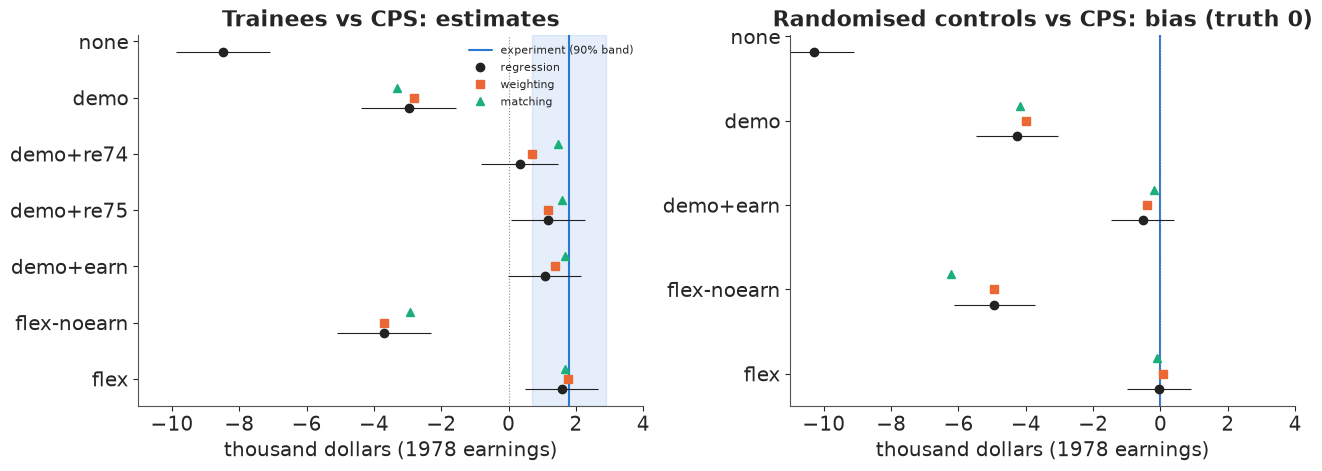

In [5]:
null = pd.concat([nsw[nsw.treat == 0].assign(treat=1), cps], ignore_index=True)   # true effect zero
lad0 = ladder(null, ["none", "demo", "demo+earn", "flex-noearn", "flex"])
print("NSW randomised controls against the CPS (true effect 0, so every number is bias):")
print(lad0.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False)
for ax, tab, truth, ttl in [(axes[0], lad, EXP, "Trainees vs CPS: estimates"),
                            (axes[1], lad0, 0.0, "Randomised controls vs CPS: bias (truth 0)")]:
    ypos = np.arange(len(tab))[::-1]
    half = 1.645 * EXP_SE if truth else 0.0
    ax.axvspan((truth - half) / 1000, (truth + half) / 1000, color=BLUE, alpha=0.12)
    ax.axvline(truth / 1000, color=BLUE, lw=1.5, label="experiment (90% band)" if truth else "truth")
    ax.axvline(0, color=MUTED, lw=0.8, ls=":")
    for k, (col, mk, c) in enumerate([("regression", "o", INK), ("weighting", "s", ORANGE), ("matching", "^", AQUA)]):
        ax.plot(tab[col] / 1000, ypos + (k - 1) * 0.18, mk, color=c, label=col, ms=6)
    ax.errorbar(tab["regression"] / 1000, ypos - 0.18, xerr=1.96 * tab["se"] / 1000, fmt="none", ecolor=INK, lw=0.8)
    ax.set_yticks(ypos, tab.index)
    ax.set(xlabel="thousand dollars (1978 earnings)", title=ttl)
for ax in axes:
    ax.set_xlim(-11, 4)
axes[0].legend(fontsize=8, loc="upper right");

On the left, the estimates climb from far below zero to the experiment's band as the earnings
history enters. On the right, the same ladder measures bias directly. With demographics only the
CPS comparison is off by \$4,264; without the earnings block the flexible set is off by \$4,936;
with demographics and earnings it is off by \$530 (\$386 by weighting, \$188 by matching), and the
flexible set by **\$40**. The two panels agree: the earnings history removes almost all of the
bias, and its absence leaves about \$4,900 by regression and weighting and \$6,200 by matching.
This test is available only because the experiment exists, and it is the strongest evidence in the
notebook. We come back to it in part G.

## C · A confounder of known strength

### C1 · The omitted-variable-bias formula

Suppose the true regression of $Y$ on treatment $D$, covariates $X$ and an unmeasured $U$ is
$Y = \tau D + X\beta + \gamma U + \varepsilon$, and we fit it without $U$. Cinelli & Hazlett
(2020) write the size of the resulting bias in two numbers that do not depend on how $U$ is
scaled: $R^2_{D\sim U\mid X}$, the share of the variance of treatment *left over after $X$* that
$U$ explains, and $R^2_{Y\sim U\mid D,X}$, the share of the outcome's leftover variance it
explains. Then

$$|\widehat{\text{bias}}| = \operatorname{se}(\hat\tau)\,\sqrt{\text{df}}\;
\sqrt{\frac{R^2_{Y\sim U\mid D,X}\;R^2_{D\sim U\mid X}}{1 - R^2_{D\sim U\mid X}}},$$

where $\hat\tau$ and its standard error come from the regression we actually ran and df is its
residual degrees of freedom. The formula is exact algebra of least squares. The direction of the
bias is a separate, third piece of information. The adjusted standard error is
$\operatorname{se}(\hat\tau)\sqrt{(1-R^2_{Y\sim U\mid D,X}) / (1-R^2_{D\sim U\mid
X})}\sqrt{\text{df}/(\text{df}-1)}$.

Partial $R^2$ can be computed for any variable we *did* measure, so the first check is to hide
one measured covariate at a time from the flexible model and compare the shift with the formula.

In [6]:
def bias_ovb(se, dof, r2yz, r2dz):
    return se * np.sqrt(dof) * np.sqrt(r2yz * r2dz / (1 - r2dz))


def se_adj(se, dof, r2yz, r2dz):
    return se * np.sqrt((1 - r2yz) / (1 - r2dz)) * np.sqrt(dof / (dof - 1))


def adjusted(est, se, dof, r2yz, r2dz, toward_zero=True):
    """Estimate, se and t after removing a confounder of the given strength."""
    b = bias_ovb(se, dof, r2yz, r2dz)
    e = est - np.sign(est) * b if toward_zero else est + np.sign(est) * b
    s = se_adj(se, dof, r2yz, r2dz)
    return e, s, e / s


def partial_r2(v, X, cols, extra=None):
    """Partial R2 of v with X[:, cols], given the other columns of X (and `extra`)."""
    others = np.delete(X, cols, axis=1)
    if extra is not None:
        others = np.column_stack([extra, others])
    r_full = ols(v, np.column_stack([others, X[:, cols]]))[3]
    r_red = ols(v, others)[3]
    return 1 - (r_full @ r_full) / (r_red @ r_red)


y_o, d_o = obs.re78.to_numpy(float), obs.treat.to_numpy(float)
X_f, names = design(obs, "flex")
EST, SE, DOF = treat_ols(y_o, d_o, X_f)
print(f"flexible regression: {EST:,.0f} (se {SE:.0f}, t {EST / SE:.2f}, df {DOF:,})")
rows = []
for col in ["re75", "re74", "u75", "black", "marr", "educ"]:
    j = names.index(col)
    e_r, s_r, df_r = treat_ols(y_o, d_o, np.delete(X_f, j, axis=1))
    r2dz, r2yz = partial_r2(d_o, X_f, [j]), partial_r2(y_o, X_f, [j], extra=d_o)
    rows.append({"hidden": col, "R2 with D": r2dz, "R2 with Y": r2yz, "estimate without it": e_r,
                 "actual shift": EST - e_r, "formula |bias|": bias_ovb(s_r, df_r, r2yz, r2dz)})
print(pd.DataFrame(rows).set_index("hidden").round(4).to_string())

flexible regression: 1,572 (se 557, t 2.82, df 16,159)


        R2 with D  R2 with Y  estimate without it  actual shift  formula |bias|
hidden                                                                         
re75       0.0004     0.0109            1425.7315      145.8651        145.8651
re74       0.0020     0.0041            1368.2558      203.3409        203.3409
u75        0.0010     0.0015            1483.2586       88.3381         88.3381
black      0.0729     0.0007            1053.6194      517.9773        517.9773
marr       0.0071     0.0004            1453.1337      118.4629        118.4629
educ       0.0013     0.0000            1578.1099       -6.5132          6.5132


Every shift matches the formula to the dollar: hiding 1975 earnings moves the estimate by \$146,
1974 earnings by \$203, the black indicator by \$518, and the formula says the same. (The formula
here uses the standard error and df of the regression *without* the variable, the analyst's
regression, which is what makes it exact.) Each earnings variable alone barely matters, because
the other years and the zero-earnings indicators stand in for it: strength is always *given
everything else in the model*. And the black indicator explains 7% of the leftover variation in
treatment but under 0.1% in earnings, so it moves the estimate by only about \$500: a confounder
needs both halves to do damage.

### C2 · Planting a confounder on the real rows

Run the formula forwards: build a synthetic $U$ on the 16,177 real rows with chosen partial $R^2$,
add it to the flexible regression, and check the estimate. Let $\tilde d$ be the treatment
residualised on $X$, $\tilde e$ the outcome residualised on $D$ and $X$, and $w$ a random vector
orthogonal to both and to $X$, all scaled to unit length. Then

$$U = \sqrt{r_d}\,\tilde d \pm \sqrt{r_y(1-r_d)}\,\tilde e + \sqrt{(1-r_d)(1-r_y)}\,w$$

has $R^2_{D\sim U\mid X} = r_d$ and $R^2_{Y\sim U\mid D,X} = r_y$ exactly, and the sign in the
middle sets whether leaving $U$ out pushes the estimate up or down. In the planted world the
"true" estimate is the one that includes $U$, and the analyst's 1,572 is the one that omits it.

In [7]:
def resid(v, M):
    return v - M @ np.linalg.lstsq(M, v, rcond=None)[0]


def plant(y, d, X, r_d, r_y, sign=+1, rng=rng):
    """A synthetic confounder with exact partial R2 r_d (with d given X) and r_y (with y given d, X)."""
    Z = np.column_stack([np.ones(len(y)), X])
    dd = resid(d, Z)
    ee = resid(y, np.column_stack([Z, d]))
    w = resid(rng.standard_normal(len(y)), np.column_stack([Z, d, ee]))
    dd, ee, w = dd / np.linalg.norm(dd), ee / np.linalg.norm(ee), w / np.linalg.norm(w)
    U = np.sqrt(r_d) * dd + sign * np.sqrt(r_y * (1 - r_d)) * ee + np.sqrt((1 - r_d) * (1 - r_y)) * w
    return U * np.sqrt(len(y))


rows = []
for r, sgn, label in [(0.01, +1, "weak, analyst too high"), (0.0066, +1, "makes the estimate just significant"),
                      (0.03, +1, "analyst too high: truth reversed"), (0.03, -1, "analyst too low: truth larger")]:
    U = plant(y_o, d_o, X_f, r, r, sgn)
    XU = np.column_stack([X_f, U])
    e_u, s_u, _ = treat_ols(y_o, d_o, XU)
    rows.append({"planted U": label, "R2 with D": partial_r2(d_o, XU, [XU.shape[1] - 1]),
                 "R2 with Y": partial_r2(y_o, XU, [XU.shape[1] - 1], extra=d_o), "estimate with U": e_u,
                 "t with U": e_u / s_u, "formula": adjusted(EST, SE, DOF, r, r, toward_zero=sgn > 0)[0]})
print(pd.DataFrame(rows).set_index("planted U").round(4).to_string())

                                     R2 with D  R2 with Y  estimate with U  t with U    formula
planted U                                                                                      
weak, analyst too high                  0.0100     0.0100         859.7633    1.5430   859.7633
makes the estimate just significant     0.0066     0.0066        1102.5913    1.9788  1102.5913
analyst too high: truth reversed        0.0300     0.0300        -585.8065   -1.0514  -585.8065
analyst too low: truth larger           0.0300     0.0300        3728.9999    6.6925  3728.9999


The planted partial $R^2$ and the estimates match the formula in every row. Read each row as a
world. If a hidden $U$ explained 1% of the
leftover variation in both treatment and earnings, the analyst's \$1,572 would hide a true \$860.
At 0.66% the truth would be \$1,103 with t of about 2.0, the edge of significance. At **3%** the
truth would be **-\$586**: the programme would hurt, and the analyst would report a significant
gain. With the other sign, the same 3% would mean the analyst *understated* a true \$3,729. A
few percent sounds small; it is enough here because training itself explains only 0.05% of the
leftover variation in earnings.

The same construction works on the zero-effect sample of B3, where the flexible estimate is
-\$40. There we ask the opposite question: could a real effect hide behind an estimate of zero?

In [8]:
y_n, d_n = null.re78.to_numpy(float), null.treat.to_numpy(float)
X_n = design(null, "flex")[0]
e0, s0, df0 = treat_ols(y_n, d_n, X_n)
print(f"randomised controls vs CPS, flexible: {e0:,.0f} (se {s0:.0f})")
for r in (0.01, 0.02, 0.03):
    U = plant(y_n, d_n, X_n, r, r, -1)
    e_u = treat_ols(y_n, d_n, np.column_stack([X_n, U]))[0]
    print(f"  a hidden U with partial R2 {r:.2f} on both sides: the analyst sees {e0:,.0f}, the truth with U is {e_u:,.0f}")

randomised controls vs CPS, flexible: -40 (se 486)
  a hidden U with partial R2 0.01 on both sides: the analyst sees -40, the truth with U is 583
  a hidden U with partial R2 0.02 on both sides: the analyst sees -40, the truth with U is 1,212
  a hidden U with partial R2 0.03 on both sides: the analyst sees -40, the truth with U is 1,847


A confounder at 3% on both sides could hide a real effect of about **\$1,850**, more than the
programme's actual effect, behind an estimate of zero. So a hidden confounder of modest strength
can **create** an effect from nothing, **hide** a real one, or **reverse** its sign, and the
formula tells us exactly how much of each. What it cannot tell us is whether such a $U$ exists.

To give "3%" a scale: the residual sd of 1978 earnings is about \$7,000, so $R^2_{Y\sim U\mid D,X}
= 0.03$ means a one-sd difference in $U$ shifts earnings by about $\sqrt{0.03}\times\$7{,}000
\approx \$1{,}200$ among men who look alike on every measured variable.

### C3 · Balance checks cannot see it

A matched analysis is usually defended with a balance table of standardised mean differences
(SMD). We match the trainees to CPS men on the
flexible propensity score and look at the balance of the measured covariates and of the planted
3% confounder.

                before  after matching
variable                              
age              -0.80           -0.03
educ             -0.68           -0.11
black             2.43           -0.12
hisp             -0.05            0.09
marr             -1.23           -0.01
nodegree          0.91            0.18
re74             -1.57           -0.01
re75             -1.75           -0.02
u74               1.49            0.03
u75               1.19            0.11
planted U (3%)    1.56            1.87
matched estimate 1,665; 116 distinct CPS men used


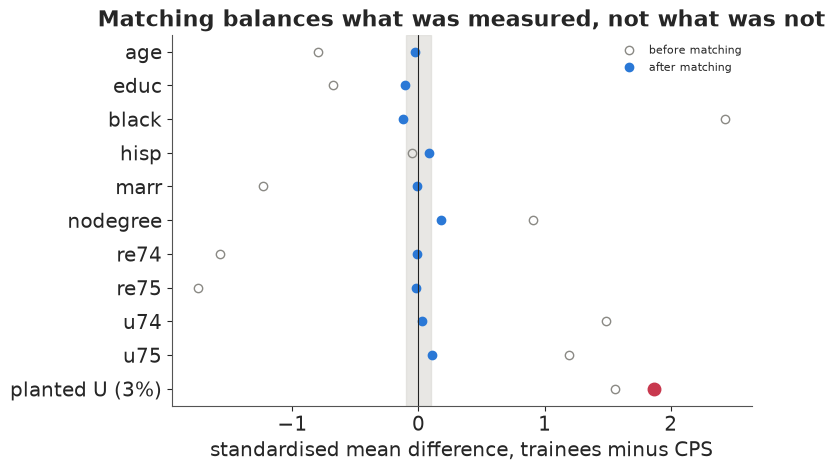

In [9]:
lp_f = logit_fit(d_o, X_f)
ti, ci = nn_match(lp_f, d_o)
U3 = plant(y_o, d_o, X_f, 0.03, 0.03, +1)
bal_vars = {c: obs[c].to_numpy(float) for c in DEMO + EARN}
bal_vars["planted U (3%)"] = U3
bal = []
for k, x in bal_vars.items():
    s_pool = np.sqrt((x[d_o == 1].var() + x[d_o == 0].var()) / 2)
    bal.append({"variable": k, "before": (x[d_o == 1].mean() - x[d_o == 0].mean()) / s_pool,
                "after matching": (x[ti].mean() - x[ci].mean()) / s_pool})
bal = pd.DataFrame(bal).set_index("variable")
print(bal.round(2).to_string())
print(f"matched estimate {np.mean(y_o[ti] - y_o[ci]):,.0f}; {len(np.unique(ci))} distinct CPS men used")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
yy = np.arange(len(bal))[::-1]
ax.axvspan(-0.1, 0.1, color=LIGHT, alpha=0.6)
ax.plot(bal["before"], yy, "o", mfc="none", color=MUTED, label="before matching")
ax.plot(bal["after matching"], yy, "o", color=BLUE, label="after matching")
ax.plot(bal.loc["planted U (3%)", "after matching"], yy[-1], "o", color=RED, ms=9)
ax.set_yticks(yy, bal.index)
ax.axvline(0, color=INK, lw=0.8)
ax.set(xlabel="standardised mean difference, trainees minus CPS",
       title="Matching balances what was measured, not what was not")
ax.legend(fontsize=8, loc="upper right");

Before matching, the covariates differ by up to 2.4 standard deviations (black) and 1.75 (1975
earnings). After matching on the flexible score, none differs by more than 0.18, a balance table
anyone would accept. The planted confounder differs by **1.87** standard deviations after
matching, more than before (1.56), because the matching pulled in CPS men who resemble trainees on
$X$ and nothing else. The balance table is silent about it, as it must be: a variable that is not
in the data cannot appear in the table. Good balance on the measured covariates is necessary and
says nothing about the unmeasured ones.

## D · How strong would the confounder have to be?

### D1 · The robustness value

Turn the formula around. Cinelli & Hazlett's **robustness value** $RV_q$ is the strength a
confounder would need, with *equal* partial $R^2$ on both sides, to reduce the estimate by a
fraction $q$ ($q = 1$ brings it to zero). With $f_q = q\,|t|/\sqrt{\text{df}}$,

$$RV_q = \tfrac12\left(\sqrt{f_q^4 + 4 f_q^2} - f_q^2\right).$$

$RV_{q,\alpha}$ asks instead for the strength that makes the adjusted estimate *statistically*
indistinguishable from $(1-q)\hat\tau$ at level $\alpha$; it is the same expression with $f_q$
replaced by $f_q - |t^*_{\alpha,\text{df}-1}|/\sqrt{\text{df}-1}$, and zero if that is negative.
The paper's Darfur example (t = 4.18 on 783 df) has $RV_1 = 13.9\%$ and $RV_{1,0.05} = 7.6\%$;
the first line below reproduces them, and on our data we check the closed form by root search.

One extreme completes the picture. If the confounder explained *all* of the leftover variation in
the outcome ($R^2_{Y\sim U\mid D,X} = 1$), the smallest $R^2_{D\sim U\mid X}$ that removes the
estimate equals the treatment's own partial $R^2$ with the outcome, $t^2/(t^2+\text{df})$.

In [10]:
def rv(t, dof, q=1.0, alpha=None):
    # closed form; with alpha it assumes |t| well below sqrt(df) (sensemakr adds an extreme-case branch otherwise)
    f = q * abs(t) / np.sqrt(dof)
    if alpha is not None:
        f = f - stats.t.ppf(1 - alpha / 2, dof - 1) / np.sqrt(dof - 1)
        if f <= 0:
            return 0.0
    return 0.5 * (np.sqrt(f ** 4 + 4 * f ** 2) - f ** 2)


def rv_numeric(est, se, dof, q=1.0, alpha=None):
    """The same by root search on the adjusted estimate or t."""
    tcrit = 0.0 if alpha is None else stats.t.ppf(1 - alpha / 2, dof - 1)

    def g(r):
        e, s, _ = adjusted(est, se, dof, r, r)
        return (e - (1 - q) * est) * np.sign(est) if alpha is None else (e - (1 - q) * est) / s * np.sign(est) - tcrit

    return optimize.brentq(g, 0.0, 1 - 1e-12)


# Cinelli & Hazlett's Darfur example, from its published summary numbers only
DF_EST, DF_SE, DF_T, DF_DOF = 0.09731, 0.02326, 4.1841, 783
print(f"Darfur: RV {rv(DF_T, DF_DOF):.1%} (published 13.9%), RV for significance {rv(DF_T, DF_DOF, alpha=0.05):.1%} (7.6%)")

T = EST / SE
RV1, RVA = rv(T, DOF), rv(T, DOF, alpha=0.05)
print(f"estimate {EST:,.0f}, t {T:.2f}; partial R2 of treatment with earnings {T ** 2 / (T ** 2 + DOF):.5f}")
print(f"RV (to zero)              {RV1:.4f}   root search {rv_numeric(EST, SE, DOF):.4f}")
print(f"RV (to non-significance)  {RVA:.4f}   root search {rv_numeric(EST, SE, DOF, alpha=0.05):.4f}")
print(f"RV (to half)              {rv(T, DOF, q=0.5):.4f}")
# the confounder that separates the estimate from the experiment pushes the other way
r_up = optimize.brentq(lambda r: adjusted(EST, SE, DOF, r, r, toward_zero=False)[0] - EXP, 1e-9, 0.5)
print(f"equal-strength confounder that would move {EST:,.0f} UP to the experiment's {EXP:,.0f}: {r_up:.4f}")

Darfur: RV 13.9% (published 13.9%), RV for significance 7.6% (7.6%)
estimate 1,572, t 2.82; partial R2 of treatment with earnings 0.00049
RV (to zero)              0.0219   root search 0.0219
RV (to non-significance)  0.0067   root search 0.0067
RV (to half)              0.0110
equal-strength confounder that would move 1,572 UP to the experiment's 1,794: 0.0031


A hidden confounder explaining **2.2%** of the leftover variation in both training and 1978
earnings would bring the estimate to zero; one explaining **0.67%** would make it statistically
indistinguishable from zero; 1.1% would halve it. The Darfur values come out as published, and
the closed forms agree with the root search to four decimals. A confounder that explained all the
leftover variation in earnings would need only 0.05% of the leftover variation in training. The
treatment-side numbers are tiny because only 1.1% of the rows are trainees: treatment has little
variance to explain, so small partial $R^2$ on that side are not small effects, and the contour
plot below uses log axes.

The last line is a reminder that the confounder to fear does not always push toward zero. Here
the experiment is *above* the estimate, and a confounder of 0.3% on both sides pointing the other
way would close the gap exactly. The analysis is two-sided even when the worry is one-sided.

### D2 · Contours and benchmarks

A robustness value is one point on a curve; the contour plot shows the adjusted estimate for
every pair of partial $R^2$. The only scale for placing a hidden confounder on it is the
covariates we measured. **Benchmarking** asks: what if
$U$ were $k$ times as strong as covariate $X_j$, in both partial $R^2$? Cinelli & Hazlett give the
bounds for a confounder orthogonal to $X$,

$$R^2_{D\sim U\mid X} \le k\,\frac{R^2_{D\sim X_j\mid X_{-j}}}{1-R^2_{D\sim X_j\mid X_{-j}}},\qquad
R^2_{Y\sim U\mid D,X} \le \eta^2\,\frac{R^2_{Y\sim X_j\mid D, X_{-j}}}{1-R^2_{Y\sim X_j\mid D, X_{-j}}},$$

with $\eta = (\sqrt{k} + \sqrt{R^2_{U\sim X_j}})/\sqrt{1-R^2_{U\sim X_j}}$ and $R^2_{U\sim X_j}$ a
small correction given in the paper. The same works for a group of covariates using their joint
partial $R^2$. The paper's benchmark table puts a confounder one, two and three times as strong
as being female at adjusted estimates of 0.075, 0.053 and 0.030; from its 1x row we back out the
female indicator's own partial $R^2$ (so the 1x bounds match by construction) and check that our
bounds give the other two rows, and the adjusted standard errors all three. Then we
benchmark against single earnings variables, the **1975 earnings block** (1975 earnings, the
zero-earnings indicator and the square), the age polynomial, the black indicator and all of the
earnings history together. The first table gives each benchmark's own partial $R^2$, the second
the bounds and adjusted estimates.

In [11]:
def bench_bounds(r2dxj, r2yxj, k=1.0):
    """Partial R2 bounds for a confounder k times as strong as a benchmark (Cinelli & Hazlett 2020)."""
    r2dz = k * r2dxj / (1 - r2dxj)
    r2zxj = k * r2dxj ** 2 / ((1 - k * r2dxj) * (1 - r2dxj))
    r2yz = ((np.sqrt(k) + np.sqrt(r2zxj)) / np.sqrt(1 - r2zxj)) ** 2 * (r2yxj / (1 - r2yxj))
    return r2dz, min(r2yz, 1.0)


# published 1x/2x/3x rows: R2 with D, R2 with Y, adjusted estimate and adjusted se
pub_female = {1: (0.00916, 0.12464, 0.0752, 0.0219), 2: (0.01833, 0.24930, 0.0529, 0.0204),
              3: (0.02749, 0.37400, 0.0304, 0.0187)}
r2d_f = pub_female[1][0] / (1 + pub_female[1][0])                          # invert the 1x treatment-side bound
eta1_sq = ((1 + r2d_f / (1 - r2d_f)) / np.sqrt(1 - (r2d_f / (1 - r2d_f)) ** 2)) ** 2
r2y_f = pub_female[1][1] / eta1_sq / (1 + pub_female[1][1] / eta1_sq)     # and the outcome-side one
for k, (bd_p, by_p, e_p, s_p) in pub_female.items():
    bd, by = bench_bounds(r2d_f, r2y_f, k)
    e_k, s_k, t_k = adjusted(DF_EST, DF_SE, DF_DOF, by, bd)
    src = "inverted to match" if k == 1 else f"published {bd_p}, {by_p}"
    print(f"Darfur, {k}x female: R2 with D {bd:.4f}, with Y {by:.4f} ({src}); adjusted estimate {e_k:.4f} ({e_p}), "
          f"se {s_k:.4f} ({s_p}), t {t_k:.2f}")

GROUPS = {"re75": ["re75"], "re74": ["re74"], "1975 earnings block": ["re75", "u75", "re75sq"],
          "age polynomial": ["age", "age2", "age3"], "black": ["black"], "marr": ["marr"],
          "all earnings": ["re74", "re75", "u74", "u75", "educ_re74", "re74sq", "re75sq"]}
bench_r2 = {g: (partial_r2(d_o, X_f, [names.index(c) for c in cols]),
                partial_r2(y_o, X_f, [names.index(c) for c in cols], extra=d_o)) for g, cols in GROUPS.items()}
print(pd.DataFrame(bench_r2, index=["own R2 with D", "own R2 with Y"]).T.round(4).to_string())
rows = []
for g, (r2d, r2y) in bench_r2.items():
    for k in ((1,) if g == "all earnings" else (1, 2, 3)):     # 2x all earnings would explain everything
        bd, by = bench_bounds(r2d, r2y, k)
        e, s, t = adjusted(EST, SE, DOF, by, bd)
        rows.append({"benchmark": f"{k}x {g}", "R2 with D": bd, "R2 with Y": by, "adjusted estimate": e, "adjusted t": t})
bench = pd.DataFrame(rows).set_index("benchmark")
print(bench.round(4).to_string())

Darfur, 1x female: R2 with D 0.0092, with Y 0.1246 (inverted to match); adjusted estimate 0.0752 (0.0752), se 0.0219 (0.0219), t 3.44
Darfur, 2x female: R2 with D 0.0183, with Y 0.2493 (published 0.01833, 0.2493); adjusted estimate 0.0529 (0.0529), se 0.0204 (0.0204), t 2.60
Darfur, 3x female: R2 with D 0.0275, with Y 0.3740 (published 0.02749, 0.374); adjusted estimate 0.0304 (0.0304), se 0.0187 (0.0187), t 1.63


                     own R2 with D  own R2 with Y
re75                        0.0004         0.0109
re74                        0.0020         0.0041
1975 earnings block         0.0028         0.0868
age polynomial              0.0123         0.0179
black                       0.0729         0.0007
marr                        0.0071         0.0004
all earnings                0.0387         0.4101
                        R2 with D  R2 with Y  adjusted estimate  adjusted t
benchmark                                                                  
1x re75                    0.0004     0.0110          1425.6192      2.5723
2x re75                    0.0008     0.0221          1279.5855      2.3214
3x re75                    0.0012     0.0331          1133.4955      2.0677
1x re74                    0.0020     0.0041          1367.4324      2.4567
2x re74                    0.0040     0.0082          1162.8525      2.0914
3x re74                    0.0061     0.0123           957.8550     

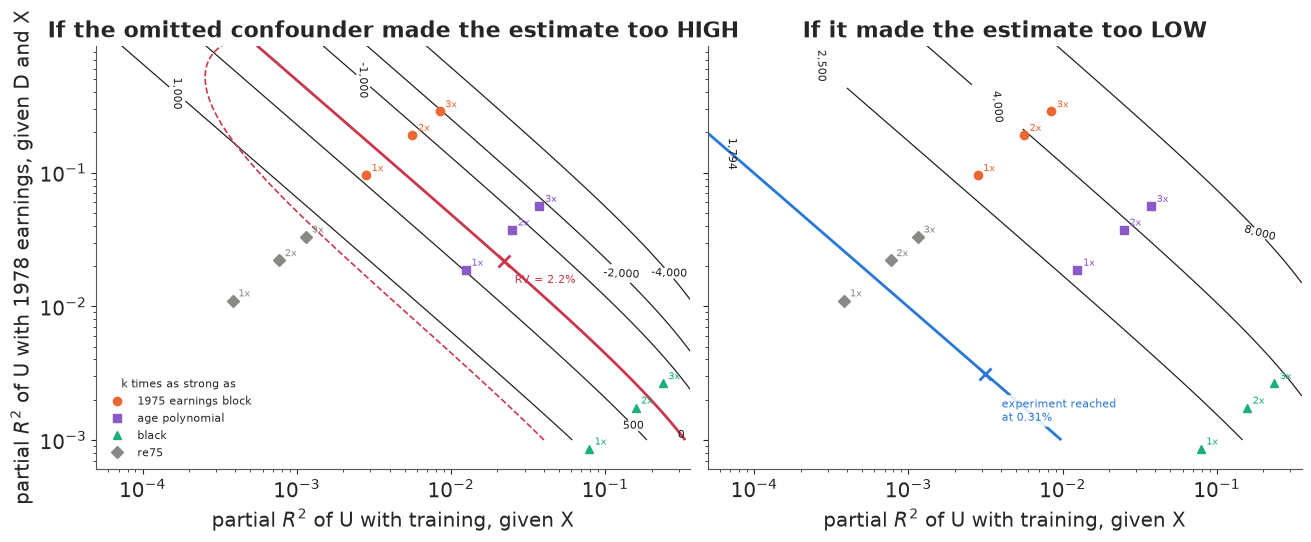

In [12]:
rd = np.logspace(-4.3, -0.45, 200)
ry = np.logspace(-3, -0.05, 160)
RD, RY = np.meshgrid(rd, ry)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, toward, ttl in [(axes[0], True, "If the omitted confounder made the estimate too HIGH"),
                        (axes[1], False, "If it made the estimate too LOW")]:
    E_, _, T_ = adjusted(EST, SE, DOF, RY, RD, toward_zero=toward)
    lev = [-4000, -2000, -1000, 0, 500, 1000] if toward else [EXP, 2500, 4000, 8000]
    cs = ax.contour(RD, RY, E_, levels=sorted(lev), colors=INK, linewidths=0.9, linestyles="solid")
    ax.clabel(cs, fmt=lambda v: f"{v:,.0f}", fontsize=8)
    zero = ax.contour(RD, RY, E_, levels=[0.0] if toward else [EXP], colors=RED if toward else BLUE, linewidths=2)
    if toward:
        ax.contour(RD, RY, T_, levels=[1.96], colors=RED, linewidths=1.2, linestyles="--")
    for g, mk, c in [("1975 earnings block", "o", ORANGE), ("age polynomial", "s", PURPLE), ("black", "^", AQUA),
                     ("re75", "D", MUTED)]:
        for k in (1, 2, 3):
            bd, by = bench_bounds(*bench_r2[g], k)
            ax.plot(bd, by, mk, color=c, ms=6, label=g if k == 1 else None)
            ax.annotate(f"{k}x", (bd, by), textcoords="offset points", xytext=(4, 3), fontsize=7, color=c)
    ax.set(xscale="log", yscale="log", xlabel=r"partial $R^2$ of U with training, given X", title=ttl)
axes[0].plot([RV1], [RV1], "x", color=RED, ms=9, mew=2)
axes[0].annotate(f"RV = {RV1:.1%}", (RV1, RV1), textcoords="offset points", xytext=(8, -16), color=RED, fontsize=8)
axes[1].plot([r_up], [r_up], "x", color=BLUE, ms=9, mew=2)
axes[1].annotate(f"experiment reached\nat {r_up:.2%}", (r_up, r_up), textcoords="offset points", xytext=(12, -34),
                 color=BLUE, fontsize=8, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
axes[0].set_ylabel(r"partial $R^2$ of U with 1978 earnings, given D and X")
axes[0].legend(fontsize=8, loc="lower left", title="k times as strong as", title_fontsize=8);

The Darfur rows match the published estimates and standard errors. In the left panel the
thick red curve is where the estimate reaches zero, the dashed one where it stops being
significant. A confounder as strong as 1975 earnings
*alone* (grey diamonds) barely matters: at three times its strength the estimate is still
\$1,133 with t = 2.1. A confounder as strong as the **1975 earnings block** is another matter: at
1x it cuts the estimate to **\$409** (t = 0.8), at 2x it reverses it (-\$757). A confounder as
strong as the age polynomial would take it to \$482, and twice as strong as being black to \$295.
The right panel shows the other direction, where the blue curve marks the experimental \$1,794:
a confounder pushing the estimate down need only sit at 0.3% on both axes, well inside the
region spanned by the 1x benchmarks.

### D3 · Two traps in benchmarking

**The benchmark's strength depends on its company.** On its own, given the rest of the model,
1975 earnings explain 1.1% of leftover earnings variation and look like a weak confounder. The
block they belong to explains 8.7%. The difference is that 1974 earnings and the zero-earnings
indicator are already in the model, so each variable's *partial* contribution is small even
though the earnings history as a whole is the strongest confounder in the data: all of it
together explains 3.9% of the leftover variation in treatment and 41% in the outcome, and a
confounder that strong would explain three quarters of the outcome's leftover variation and
swamp the estimate (the last row, -\$11,000). Benchmarking against
the weakest-looking member of a correlated group understates what a hidden confounder of that
kind could do. Benchmark the group.

**A benchmark is only as good as the analogy.** Go back to the analyst of part B2 who never
measured earnings and got -\$3,690. How robust would that estimate have looked, benchmarked
against what the analyst did measure?

In [13]:
earn_cols = [names.index(c) for c in GROUPS["all earnings"]]
X_ne = np.delete(X_f, earn_cols, axis=1)
names_ne = [n for i, n in enumerate(names) if i not in earn_cols]
e_ne, s_ne, df_ne = treat_ols(y_o, d_o, X_ne)
print(f"the analyst without earnings: {e_ne:,.0f} (t {e_ne / s_ne:.2f}); RV {rv(e_ne / s_ne, df_ne):.3f}, "
      f"RV for significance {rv(e_ne / s_ne, df_ne, alpha=0.05):.3f}")
rows = []
for col in ["age", "educ", "black", "marr", "nodegree", "hisp"]:
    j = names_ne.index(col)
    r2d, r2y = partial_r2(d_o, X_ne, [j]), partial_r2(y_o, X_ne, [j], extra=d_o)
    for k in (1, 3):
        bd, by = bench_bounds(r2d, r2y, k)
        rows.append({"benchmark": f"{k}x {col}", "R2 with D": bd, "R2 with Y": by,
                     "adjusted estimate": adjusted(e_ne, s_ne, df_ne, by, bd)[0]})
print(pd.DataFrame(rows).set_index("benchmark").round(4).to_string())
r2d_h, r2y_h = bench_r2["all earnings"]
print(f"the hidden earnings block actually had R2 with D {r2d_h:.3f} and R2 with Y {r2y_h:.3f}")

the analyst without earnings: -3,690 (t -5.19); RV 0.040, RV for significance 0.025
             R2 with D  R2 with Y  adjusted estimate
benchmark                                           
1x age          0.0036     0.0043         -3336.1485
3x age          0.0108     0.0128         -2624.0062
1x educ         0.0020     0.0018         -3518.8578
3x educ         0.0060     0.0054         -3174.9719
1x black        0.0850     0.0054         -1673.0191
3x black        0.2549     0.0166          3132.6725
1x marr         0.0086     0.0150         -2657.3711
3x marr         0.0259     0.0450          -563.7400
1x nodegree     0.0054     0.0006         -3530.4472
3x nodegree     0.0163     0.0017         -3208.1083
1x hisp         0.0003     0.0007         -3652.3823
3x hisp         0.0008     0.0020         -3576.5501
the hidden earnings block actually had R2 with D 0.039 and R2 with Y 0.410


The analyst without earnings would have reported a robustness value of 4.0%: a confounder would
need 4% of the leftover variation on both sides to remove the estimate. Against demographic
benchmarks that looks safe. Three times the strength of marriage, the strongest demographic on
the outcome side, gives a confounder with 4.5% of outcome variation and leaves the estimate at
-\$564; three times schooling moves it by about \$500 and three times age by about \$1,000, to
-\$2,600. Only "three times as strong as being black" reverses it, by being a huge confounder on
the treatment side. The real hidden confounder, the earnings history, had **41%** of the outcome
variation, nine times what any demographic benchmark at 3x allowed: the thing we did not measure
was of a different kind from everything we did. A benchmark is an argument, not a measurement.

## E · Other yardsticks

### E1 · E-values for employment

For a binary outcome the E-value of VanderWeele & Ding (2017), $E = RR + \sqrt{RR\,(RR-1)}$ for
$RR \ge 1$, is the risk ratio a confounder would need with both treatment and outcome to explain
the association away (E101). We compare it across covariate sets. The outcome is employment in
1978 (any earnings), the risk in the trainees is observed, and the risk they would have had
untreated comes from the odds-weighted CPS men. A bootstrap (200 resamples within each group, with
the propensity model refitted) gives the intervals.

In [14]:
def e_value(rr):
    rr = 1 / rr if rr < 1 else rr
    return rr + np.sqrt(rr * (rr - 1))


def e_value_ci(rr, lo, hi):
    if (rr >= 1 and lo <= 1) or (rr < 1 and hi >= 1):
        return 1.0
    return e_value(lo if rr >= 1 else hi)


emp_o = obs.emp78.to_numpy(float)
rng_b = np.random.default_rng(RANDOM_SEED + 1)
t_idx, c_idx = np.flatnonzero(d_o == 1), np.flatnonzero(d_o == 0)


def rr_att(yb, d, X):
    w = np.exp(logit_fit(d, X))
    return yb[d == 1].mean() / np.average(yb[d == 0], weights=w[d == 0])


rows = []
for spec in ("demo", "demo+earn", "flex"):
    Xs_ = design(obs, spec)[0]
    rr = rr_att(emp_o, d_o, Xs_)
    boot = []
    for _ in range(200):
        ii = np.r_[rng_b.choice(t_idx, len(t_idx)), rng_b.choice(c_idx, len(c_idx))]
        boot.append(rr_att(emp_o[ii], d_o[ii], Xs_[ii]))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"covariates": spec, "risk ratio": rr, "2.5%": lo, "97.5%": hi, "E-value": e_value(rr),
                 "E-value of CI": e_value_ci(rr, lo, hi)})
rows.append({"covariates": "experiment", "risk ratio": p1_e / p0_e, "E-value": e_value(p1_e / p0_e)})
evt = pd.DataFrame(rows).set_index("covariates")
print(evt.round(2).to_string())
_, _, _, res_f = ols(y_o, np.column_stack([d_o, X_f]))
for lab, sdv in [("CPS men", y_o[d_o == 0].std()), ("leftover (regression residual)", res_f.std()),
                 ("NSW controls", nsw.re78[nsw.treat == 0].std())]:
    rr_c = np.exp(0.91 * EST / sdv)
    print(f"1978 earnings as a risk ratio exp(0.91 x effect/sd), sd of {lab} = {sdv:,.0f}: RR {rr_c:.2f}, E {e_value(rr_c):.2f}")

            risk ratio  2.5%  97.5%  E-value  E-value of CI
covariates                                                 
demo              0.89  0.81   0.98     1.48           1.14
demo+earn         1.10  0.98   1.22     1.42           1.00
flex              1.17  0.95   1.43     1.61           1.00
experiment        1.17   NaN    NaN     1.62            NaN
1978 earnings as a risk ratio exp(0.91 x effect/sd), sd of CPS men = 9,647: RR 1.16, E 1.59
1978 earnings as a risk ratio exp(0.91 x effect/sd), sd of leftover (regression residual) = 6,977: RR 1.23, E 1.76
1978 earnings as a risk ratio exp(0.91 x effect/sd), sd of NSW controls = 5,484: RR 1.30, E 1.92


The flexible analysis gives a risk ratio of 1.17, the same as the experiment, with an E-value of
**1.61**: a confounder associated with both training and employment by risk ratios of 1.6 each
could explain it away, and since the interval includes 1, the E-value of the interval is 1. The
instructive row is the first. With demographics only, the risk ratio is **0.89**, pointing the
wrong way, and its E-value is **1.48**, about as "robust" as the right answer's 1.61, with an
interval that excludes 1 (E-value of the interval 1.14). An E-value says how strong a confounder
would have to be to move an estimate to the null, not which way the bias runs or whether such a
confounder is plausible.

For 1978 earnings themselves, converted to a risk ratio $\exp(0.91\,\delta)$, say which sd
defines $\delta$: the E-value runs from 1.59 to 1.92 depending on it.

### E2 · Rosenbaum bounds for matched pairs

Rosenbaum's approach starts from a matched design. Pair each trainee with one CPS man with nearly
the same propensity score. If there were no hidden bias, the two men in a pair would have had
equal chances of being the trainee. Rosenbaum (2002) supposes instead that their odds of treatment
may differ by up to a factor $\Gamma$ because of something unmeasured, and bounds the p-value of a
test of no effect over all such assignments. For Wilcoxon's signed-rank statistic $T$, the sum of
the ranks of $|y_{\text{trainee}} - y_{\text{match}}|$ over pairs where the trainee earned more,
the worst case treats each pair as positive with probability $p^+ = \Gamma/(1+\Gamma)$:

$$\mathbb{E}[T] = p^+ \sum_i r_i,\qquad \operatorname{Var}[T] = p^+(1-p^+)\sum_i r_i^2,$$

and the upper bound on the one-sided p-value follows from a normal approximation. The
**sensitivity value** of the result, $\Gamma^*$, is the $\Gamma$ at which that bound reaches 0.05:
the amount of hidden bias at which significance is lost.

We start with the design most analysts would build first, greedy one-to-one matching without
replacement on the flexible propensity score, and as a calibration read the *randomised
experiment* as a matched study paired the same way.

scipy's Wilcoxon (normal approx.) for the observational pairs: 0.3818; ours at Gamma = 1: 0.3818
                                          pairs  mean difference   median  p at Gamma=1  Gamma*
design                                                                                         
built first: score, greedy                  185          729.980    0.000         0.382     NaN
chosen after looking: Mahalanobis, exact    153         1347.105  395.342         0.035   1.032
the experiment, read as pairs               185         1759.819  485.230         0.010   1.125
greedy design: mean |logit-score gap| 1.104 in the first 92 pairs, 0.145 in the last 92; with replacement 0.020
amplification of the experiment's Gamma* 1.13: Lambda 1.5 on treatment <-> Delta 1.84 on the outcome
amplification of the experiment's Gamma* 1.13: Lambda 2.0 on treatment <-> Delta 1.43 on the outcome
amplification of the experiment's Gamma* 1.13: Lambda 3.0 on treatment <-> Delta 1.27 on the outcome


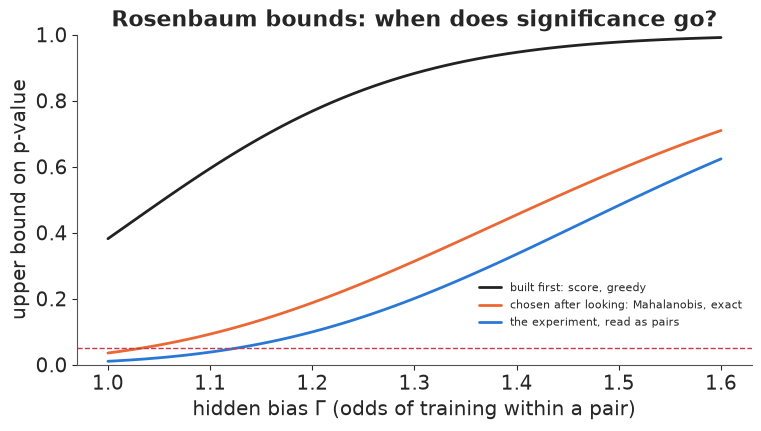

In [15]:
def wilcoxon_gamma_p(diff, gamma):
    """Upper bound on the one-sided p-value of Wilcoxon's signed-rank test under hidden bias gamma."""
    d = diff[diff != 0]
    r = stats.rankdata(np.abs(d))
    p = gamma / (1 + gamma)
    z = (r[d > 0].sum() - p * r.sum()) / np.sqrt(p * (1 - p) * (r ** 2).sum())
    return stats.norm.sf(z)


def gamma_star(diff, alpha=0.05):
    if wilcoxon_gamma_p(diff, 1.0) > alpha:
        return np.nan
    return optimize.brentq(lambda g: wilcoxon_gamma_p(diff, g) - alpha, 1.0, 50.0)


tt, mm = nn_match(lp_f, d_o, replace=False)
pairs_obs = y_o[tt] - y_o[mm]
lp_e = logit_fit(d_e, design(nsw, "demo+earn")[0])
te, me = nn_match(lp_e, d_e, replace=False)
pairs_exp = y_e[te] - y_e[me]
print(f"scipy's Wilcoxon (normal approx.) for the observational pairs: "
      f"{stats.wilcoxon(pairs_obs[pairs_obs != 0], alternative='greater', method='approx', correction=False).pvalue:.4f}"
      f"; ours at Gamma = 1: {wilcoxon_gamma_p(pairs_obs, 1.0):.4f}")


def maha_match(cal=0.25):
    """Mahalanobis matching on age, schooling and earnings, exact on u74, u75, black, inside a score caliper."""
    Zm = obs[["age", "educ", "re74", "re75"]].to_numpy(float)
    Si = np.linalg.inv(np.cov(Zm[c_idx].T))
    ex = obs[["u74", "u75", "black"]].to_numpy()
    used = np.zeros(len(obs), bool)
    out_t, out_c = [], []
    for i in t_idx[np.argsort(-lp_f[t_idx])]:
        ok = c_idx[(~used[c_idx]) & (np.abs(lp_f[c_idx] - lp_f[i]) < cal * lp_f.std()) & (ex[c_idx] == ex[i]).all(1)]
        if len(ok):
            dz = Zm[ok] - Zm[i]
            j = ok[np.argmin(np.einsum("ij,jk,ik->i", dz, Si, dz))]
            used[j] = True
            out_t.append(i)
            out_c.append(j)
    return np.array(out_t), np.array(out_c)


tm, cm = maha_match()
pairs_maha = y_o[tm] - y_o[cm]
designs = {"built first: score, greedy": pairs_obs, "chosen after looking: Mahalanobis, exact": pairs_maha,
           "the experiment, read as pairs": pairs_exp}
rows = [{"design": k, "pairs": len(v), "mean difference": v.mean(), "median": np.median(v), "p at Gamma=1": wilcoxon_gamma_p(v, 1.0),
         "Gamma*": gamma_star(v)} for k, v in designs.items()]
print(pd.DataFrame(rows).set_index("design").round(3).to_string())
gap_g = np.abs(lp_f[tt] - lp_f[mm])                  # greedy pairs, in the order they were formed
print(f"greedy design: mean |logit-score gap| {gap_g[:92].mean():.3f} in the first 92 pairs, "
      f"{gap_g[93:].mean():.3f} in the last 92; with replacement {np.abs(lp_f[ti] - lp_f[ci]).mean():.3f}")
G_EXP = gamma_star(pairs_exp)
for lam in (1.5, 2.0, 3.0):
    print(f"amplification of the experiment's Gamma* {G_EXP:.2f}: Lambda {lam} on treatment <-> Delta "
          f"{(G_EXP * lam - 1) / (lam - G_EXP):.2f} on the outcome")

gam = np.linspace(1, 1.6, 61)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (k, v), c in zip(designs.items(), [INK, ORANGE, BLUE]):
    ax.plot(gam, [wilcoxon_gamma_p(v, g) for g in gam], color=c, lw=2, label=k)
ax.axhline(0.05, color=RED, ls="--", lw=1)
ax.set(xlabel=r"hidden bias $\Gamma$ (odds of training within a pair)", ylabel="upper bound on p-value",
       title="Rosenbaum bounds: when does significance go?", ylim=(0, 1))
ax.legend(fontsize=8, loc="lower right", bbox_to_anchor=(1.0, 0.08));

The design built first gives 185 pairs with a mean difference of \$730 and a Wilcoxon p-value of
**0.38** with no hidden bias at all. $\Gamma^*$ is undefined: a test that does not reject even
with no hidden bias has no significance for a hidden bias to remove. (Our bound at $\Gamma = 1$
equals SciPy's Wilcoxon test, a check of the code.) The poor pairs are the ones formed first, for
the trainees with the highest scores: the mean logit-score gap within a pair is 1.10 in the first
92 pairs, 0.15 in the last 92 and 0.02 with replacement. Too few CPS men look like the most
typical trainees to give each his own.

A tighter design, Mahalanobis matching on age, schooling and earnings with exact matches on the
zero-earnings indicators and race inside a propensity caliper, gives 153 pairs, a mean difference
of \$1,347, p = 0.035 and $\Gamma^* = $ **1.03**. We found it after seeing the first design fail,
and even so a hidden bias that raised one man's odds of training by 3% over his partner's would
remove significance.

The calibration row changes how that sounds. The randomised experiment itself, paired the same
way, has $\Gamma^* = $ **1.13**. A study of 185 pairs of men with very noisy earnings, a quarter
to a third of whom earned nothing in 1978, cannot be insensitive to hidden bias, whatever its
design, because its evidence was never strong: $\Gamma^*$ mixes bias with the size of the effect
and the study. Rosenbaum's **design sensitivity** separates them: it is the limit of $\Gamma^*$ as
the number of pairs grows, for a given effect and no bias, a property of the design and the effect
rather than of one sample. The experiment row is a finite-sample stand-in for it: what this many
pairs, with this effect and no bias, can reach. The amplification of Rosenbaum & Silber (2009)
splits $\Gamma = 1.13$ in two: a confounder that doubled the odds of training ($\Lambda = 2$)
would need to raise the odds of a higher outcome within a pair by a factor $\Delta = 1.43$.

## F · Beliefs about the confounder as priors

Every tool so far answers "how strong would it have to be?" and leaves the reader to decide
whether it is that strong. A Bayesian sensitivity model writes that judgement into a prior, and
**the data do not update that prior**. We fit three
versions, with earnings in thousands of dollars and the flexible covariates standardised.

### F1 · A latent confounder the data cannot see

As in E101 part G, we start with a bias the data cannot learn, written as a latent confounder.
Let $U$
be a standardised confounder with mean $\delta$ higher in the trainees (in standard
deviations) and an effect $\gamma$ (thousand dollars per standard deviation) on 1978 earnings:

$$U \mid D \sim N(\delta D, 1),\qquad Y = a + \tau D + X\beta + \gamma U + \varepsilon,\qquad
\varepsilon \sim N(0, \sigma^2).$$

Integrating $U$ out gives $Y \mid D, X \sim N\big(a + (\tau + \gamma\delta) D + X\beta,\; \sigma^2
+ \gamma^2\big)$. The data see the sum $\theta = \tau + \gamma\delta$, the usual regression
coefficient, and the total variance $\sigma^2+\gamma^2$, nothing else. This is a partially
identified model in Gustafson's sense: more data shrink the uncertainty about $\theta$ but never
separate $\tau$ from the bias $\gamma\delta$. We sample $\theta$ and derive $\tau = \theta -
\gamma\delta$, which avoids a ridge. The priors $\gamma \sim N(0, 2)$ and $\delta \sim N(0, 1)$
say that a confounder could shift earnings by a couple of thousand dollars per standard deviation
and differ between the groups by up to about two standard deviations.

Before fitting, the prior on the quantity that matters: the bias $\gamma\delta$.

In [16]:
X_std = (X_f - X_f.mean(0)) / X_f.std(0)
y_k = y_o / 1000.0
pri = np.random.default_rng(RANDOM_SEED + 2)
bias_prior = pri.normal(0, 2, 20000) * pri.normal(0, 1, 20000)
print(f"prior bias gamma*delta (k$): sd {bias_prior.std():.2f}, 5-95% [{np.percentile(bias_prior, 5):.2f}, "
      f"{np.percentile(bias_prior, 95):.2f}], P(|bias| > 1.5) {np.mean(np.abs(bias_prior) > 1.5):.2f}")

coords = {"cov": names}
with pm.Model(coords=coords) as m_latent:
    a = pm.Normal("a", 15.0, 10.0)
    b = pm.Normal("b", 0.0, 10.0, dims="cov")
    theta = pm.Normal("theta", 0.0, 5.0)              # what the data see: tau + gamma * delta
    gamma = pm.Normal("gamma", 0.0, 2.0)              # k$ per sd of U
    delta = pm.Normal("delta", 0.0, 1.0)              # trainees minus comparison men, sd of U
    sigma = pm.HalfNormal("sigma", 10.0)
    tau = pm.Deterministic("tau", theta - gamma * delta)
    pm.Normal("y", a + theta * d_o + pt.dot(X_std, b), pt.sqrt(sigma ** 2 + gamma ** 2), observed=y_k)
    t0 = time.time()
    idata_latent = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    print(f"sampled in {time.time() - t0:.0f} s, {idata_latent.posterior.attrs.get('tuning_steps', '?')} tuning steps")
print(f"divergences {int(idata_latent.sample_stats['diverging'].sum())}")
print(az.summary(idata_latent, var_names=["theta", "tau", "gamma", "delta", "sigma"], round_to=3).to_string())

prior bias gamma*delta (k$): sd 2.02, 5-95% [-3.13, 3.21], P(|bias| > 1.5) 0.29


sampled in 16 s, 400 tuning steps
divergences 0
        mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
theta  1.509  0.552     0.615     2.384  4682.848  3337.253  1.001      0.008    0.009
tau    1.484  2.194    -1.985     4.865  5151.384  2010.274  1.003      0.030    0.092
gamma  0.137  2.194    -3.368     3.789   606.263   449.635  1.006      0.091    0.096
delta  0.036  1.011    -1.600     1.665  5802.764  2581.637  1.001      0.013    0.019
sigma  6.597  0.621     5.526     7.006   431.087   409.029  1.003      0.040    0.102


gamma: prior sd 2.00, posterior sd 2.19
delta: prior sd 1.00, posterior sd 1.01
tau: 90% interval [-2.15, 5.01] k$; theta: [0.59, 2.41]


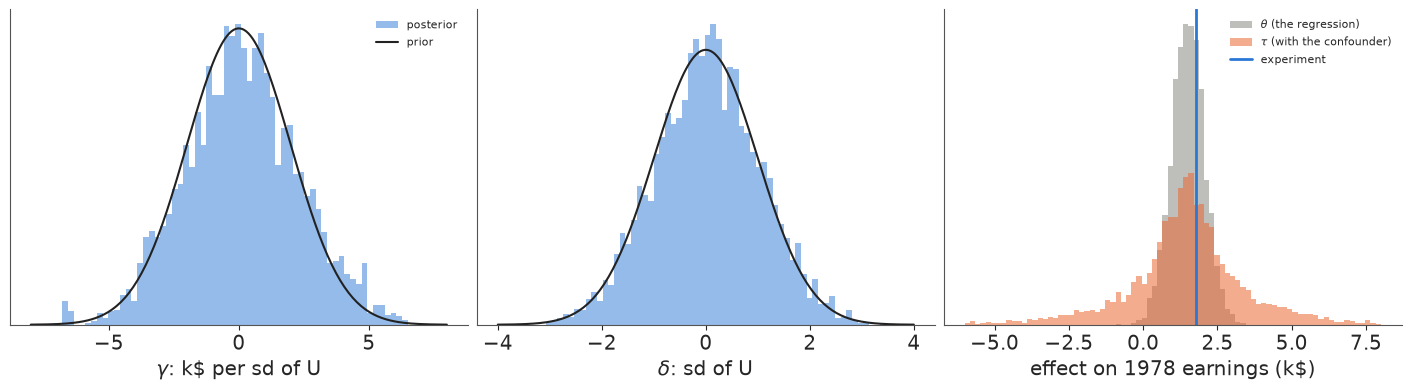

In [17]:
post = {v: idata_latent.posterior[v].values.ravel() for v in ("theta", "tau", "gamma", "delta")}
for v, sd_ in (("gamma", 2.0), ("delta", 1.0)):
    print(f"{v}: prior sd {sd_:.2f}, posterior sd {post[v].std():.2f}")
print(f"tau: 90% interval [{np.percentile(post['tau'], 5):.2f}, {np.percentile(post['tau'], 95):.2f}] k$; "
      f"theta: [{np.percentile(post['theta'], 5):.2f}, {np.percentile(post['theta'], 95):.2f}]")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, v, sd_, lab in [(axes[0], "gamma", 2.0, r"$\gamma$: k\$ per sd of U"), (axes[1], "delta", 1.0, r"$\delta$: sd of U")]:
    grid = np.linspace(-4 * sd_, 4 * sd_, 200)
    ax.hist(post[v], bins=60, density=True, color=BLUE, alpha=0.5, label="posterior")
    ax.plot(grid, stats.norm.pdf(grid, 0, sd_), color=INK, lw=1.5, label="prior")
    ax.set(xlabel=lab, yticks=[])
axes[0].legend(fontsize=8)
for v, c, lab in [("theta", MUTED, r"$\theta$ (the regression)"), ("tau", ORANGE, r"$\tau$ (with the confounder)")]:
    axes[2].hist(post[v], bins=80, range=(-6, 8), density=True, color=c, alpha=0.55, label=lab)
axes[2].axvline(EXP / 1000, color=BLUE, lw=2, label="experiment")
axes[2].set(xlabel="effect on 1978 earnings (k$)", yticks=[])
axes[2].legend(fontsize=8);

The prior allows a bias of up to about \$3,200 either way (90%) and gives a 29% chance that it
exceeds \$1,500, the size of the estimate itself: a statement of real doubt. The sampler had no
difficulty (no divergences, r_hat at most about 1.01), though $\gamma$ and $\sigma$, which share
one variance, mix more slowly (bulk ESS 400-700). $\theta$ comes out at about 1.5 thousand dollars
with sd 0.55, close to the least-squares \$1,572. The posterior of $\delta$ is its prior. The
posterior of $\gamma$ keeps its prior's centre and shape, slightly wider (sd 2.2 against 2.0)
because the data fix only the total $\sigma^2 + \gamma^2$. The effect $\tau$ is then the
regression estimate blurred by the prior on the bias, with a 90% interval of about -2 to 5
thousand dollars: it covers the experiment but is far too wide to act on. Nothing in the fit is
wrong; the width is the prior's, and a sensitivity model is only as useful as the argument behind
its prior.

### F2 · Priors from benchmarks

Part D gave that argument a form: a hidden confounder no stronger than *k times the 1975
earnings block*. Write the model in Cinelli & Hazlett's terms so that the prior can say exactly
that. Let $\rho_d$ and $\rho_y$ be the signed partial correlations of $U$ with training (given
$X$) and with earnings (given $D$ and $X$). The bias in the regression coefficient is then

$$\text{bias} = \frac{\rho_y\,\rho_d}{\sqrt{1-\rho_d^2}}\;\frac{s}{\operatorname{sd}(\tilde d)},$$

with $s$ the residual sd of earnings and $\operatorname{sd}(\tilde d)$ the sd of treatment after
regressing it on $X$. Squared, $\rho$'s are the partial $R^2$ of part C. We give $\rho_d$ and
$\rho_y$ uniform priors on $\pm$ the benchmark bounds for $k = 1$ and for $k = 3$, two scenarios
in one model sharing the regression, and report $\tau = \theta - \text{bias}$.

sd of training after X: 0.0985
                         |rho_d| max  |rho_y| max
up to 1x the 1975 block        0.053        0.309
up to 3x the 1975 block        0.092        0.536


sampled in 11 s; divergences 0
                                 mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
theta                           1.510  0.549     0.636     2.394  4565.618  3137.265  1.001      0.008    0.008
tau[up to 1x the 1975 block]    1.487  0.674     0.382     2.547  2955.779  2738.542  1.000      0.012    0.009
tau[up to 3x the 1975 block]    1.513  1.272    -0.527     3.610  2011.984  2237.304  1.002      0.028    0.021
rho_d[up to 1x the 1975 block]  0.001  0.031    -0.047     0.047  5589.266  2640.042  1.004      0.000    0.000
rho_d[up to 3x the 1975 block] -0.000  0.053    -0.082     0.081  5927.277  2512.302  1.002      0.001    0.001
                         tau mean     5%    95%  P(tau > 0)  covers 1.794  sd rho_d post  sd rho_d prior
prior                                                                                                   
up to 1x the 1975 block     1.487  0.358  2.587       0.985          True          0.03

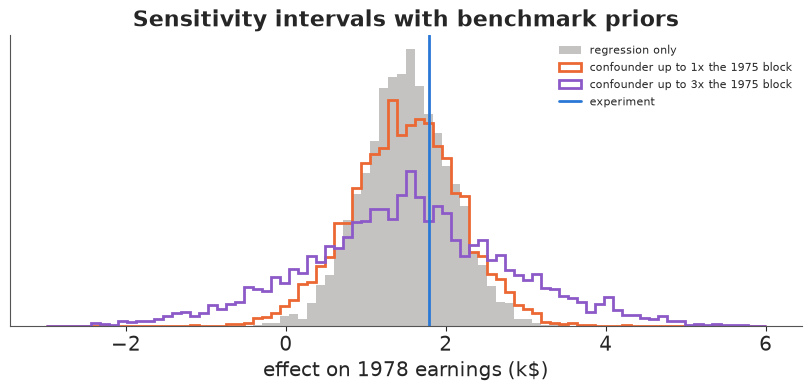

In [18]:
Z1 = np.column_stack([np.ones(len(y_k)), X_std])
sd_dres = resid(d_o, Z1).std()
lim = np.array([[np.sqrt(v) for v in bench_bounds(*bench_r2["1975 earnings block"], k)] for k in (1, 3)])
SCEN = ["up to 1x the 1975 block", "up to 3x the 1975 block"]
print(f"sd of training after X: {sd_dres:.4f}")
print(pd.DataFrame(lim, index=SCEN, columns=["|rho_d| max", "|rho_y| max"]).round(3).to_string())
with pm.Model(coords={"cov": names, "scenario": SCEN}) as m_bench:
    a = pm.Normal("a", 15.0, 10.0)
    b = pm.Normal("b", 0.0, 10.0, dims="cov")
    theta = pm.Normal("theta", 0.0, 5.0)
    s = pm.HalfNormal("s", 10.0)
    pm.Normal("y", a + theta * d_o + pt.dot(X_std, b), s, observed=y_k)
    rho_d = pm.Uniform("rho_d", lower=-lim[:, 0], upper=lim[:, 0], dims="scenario")
    rho_y = pm.Uniform("rho_y", lower=-lim[:, 1], upper=lim[:, 1], dims="scenario")
    bias = pm.Deterministic("bias", rho_y * rho_d / pt.sqrt(1 - rho_d ** 2) * s / sd_dres, dims="scenario")
    pm.Deterministic("tau", theta - bias, dims="scenario")
    t0 = time.time()
    idata_bench = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    print(f"sampled in {time.time() - t0:.0f} s; divergences {int(idata_bench.sample_stats['diverging'].sum())}")
print(az.summary(idata_bench, var_names=["theta", "tau", "rho_d"], round_to=3).to_string())
rows = []
for sc in SCEN:
    tv = idata_bench.posterior["tau"].sel(scenario=sc).values.ravel()
    rdv = idata_bench.posterior["rho_d"].sel(scenario=sc).values.ravel()
    lo, hi = np.percentile(tv, [5, 95])
    rows.append({"prior": sc, "tau mean": tv.mean(), "5%": lo, "95%": hi, "P(tau > 0)": np.mean(tv > 0),
                 "covers 1.794": lo <= EXP / 1000 <= hi, "sd rho_d post": rdv.std(),
                 "sd rho_d prior": 2 * lim[SCEN.index(sc), 0] / np.sqrt(12)})
bench_bayes = pd.DataFrame(rows).set_index("prior")
print(bench_bayes.round(3).to_string())
for k in (1, 3):
    e_w, s_w, _ = adjusted(EST, SE, DOF, *bench_bounds(*bench_r2["1975 earnings block"], k)[::-1])
    print(f"worst case at {k}x (part D) with its own sampling error: {e_w:,.0f}, "
          f"90% interval {e_w - 1.645 * s_w:,.0f} to {e_w + 1.645 * s_w:,.0f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(idata_bench.posterior["theta"].values.ravel(), bins=80, range=(-3, 6), density=True, color=MUTED, alpha=0.5,
        label="regression only")
for sc, c in zip(SCEN, [ORANGE, PURPLE]):
    ax.hist(idata_bench.posterior["tau"].sel(scenario=sc).values.ravel(), bins=80, range=(-3, 6), density=True,
            histtype="step", color=c, lw=2, label=f"confounder {sc}")
ax.axvline(EXP / 1000, color=BLUE, lw=2, label="experiment")
ax.set(xlabel="effect on 1978 earnings (k$)", yticks=[], title="Sensitivity intervals with benchmark priors")
ax.legend(fontsize=8);

Sampling was clean (no divergences). The bounds are 0.053 on $\rho_d$ and 0.31 on $\rho_y$ at
1x. With a confounder no
stronger than the 1975 earnings block, in either direction, the 90% interval for the effect is
**\$360 to \$2,590** and the probability that the programme helped is 0.98. Allowing three times
that strength widens it to **-\$600 to \$3,690**, with $P(\tau > 0) = 0.89$. Both cover the
experiment's \$1,794. The posterior sd of $\rho_d$ equals the uniform prior's to the third
decimal: these parameters do not appear in the likelihood at all.

A uniform prior on two correlations puts most of the mass for their product near zero, so the
intervals sit inside part D's worst case plus its sampling error: at 1x that worst case is \$409
with a 90% interval starting at about
-\$460, against \$360 here, and at 3x it starts near -\$2,700 rather than -\$600. And we chose
the benchmark after seeing the data; in a real analysis the range is written down first.

### F3 · A latent confounder that learns too much

McCandless, Gustafson & Levy (2007) proposed a fully Bayesian model with a **binary** unmeasured
confounder: $U \sim \text{Bernoulli}(\pi_D)$ with a prevalence that differs by treatment, and an
outcome model with $U$ in it. We try the same idea on employment in 1978, a binary outcome with a
logistic model:

$$\operatorname{logit}\pi_D = \eta_0 + \eta_1 D,\qquad
P(Y=1\mid D, X) = \pi_D\,\operatorname{logit}^{-1}(\ell + \gamma) +
(1-\pi_D)\operatorname{logit}^{-1}(\ell),
\quad \ell = a + \tau D + X\beta,$$

with $U$ summed out. We fix the sign $\gamma > 0$ with a half-normal prior so that $U = 1$ always
means "more likely to work" and the labels of $U$ cannot swap. The priors are weak but not vague:
$\gamma \sim \text{HalfNormal}(1)$, $\eta_1 \sim N(0, 1)$. If the model behaved like F1 and F2,
their posteriors would stay near their priors. A plain logistic regression and the experiment
give yardsticks for $\tau$, a log odds ratio. The fit takes about a minute, so we keep 500 draws
per chain.

In [19]:
Zl = np.column_stack([np.ones(len(d_o)), d_o, X_std])
TAU_LOGIT = logit_newton(emp_o, Zl)[1]
print(f"plain logistic regression, log odds ratio of training: {TAU_LOGIT:.2f}; experiment: {EXP_LOR:.2f}")
with pm.Model(coords={"cov": names}) as m_binary:
    a = pm.Normal("a", 0.0, 2.0)
    b = pm.Normal("b", 0.0, 1.0, dims="cov")
    tau = pm.Normal("tau", 0.0, 1.0)
    gamma = pm.HalfNormal("gamma", 1.0)
    eta0 = pm.Normal("eta0", 0.0, 1.5)
    eta1 = pm.Normal("eta1", 0.0, 1.0)
    lin = a + tau * d_o + pt.dot(X_std, b)
    pi = pm.math.invlogit(eta0 + eta1 * d_o)
    pm.Bernoulli("y", p=pi * pm.math.invlogit(lin + gamma) + (1 - pi) * pm.math.invlogit(lin), observed=emp_o)
    t0 = time.time()
    idata_bin = pm.sample(draws=500, random_seed=RANDOM_SEED, progressbar=False)
    print(f"sampled in {time.time() - t0:.0f} s; divergences {int(idata_bin.sample_stats['diverging'].sum())}, "
          f"per chain {idata_bin.sample_stats['diverging'].sum('draw').values}")
print(az.summary(idata_bin, var_names=["tau", "gamma", "eta0", "eta1"], round_to=3).to_string())
for v in ("tau", "gamma", "eta1"):
    print(f"  {v}: per-chain means {np.round(idata_bin.posterior[v].mean('draw').values, 2)}, "
          f"sds {np.round(idata_bin.posterior[v].std('draw').values, 2)}")

plain logistic regression, log odds ratio of training: 0.82; experiment: 0.53


sampled in 77 s; divergences 23, per chain [ 0  0  0 23]
        mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
tau    1.864  0.751     0.549     2.860     7.189    10.246  1.532      0.325    0.146
gamma  4.481  2.337     0.131     6.338     7.278    10.397  1.540      1.147    0.656
eta0   1.938  1.230    -0.985     2.642    21.979    10.555  1.448      0.390    0.443
eta1  -1.052  0.708    -1.735     0.446    15.314     9.870  1.270      0.231    0.228
  tau: per-chain means [2.23 2.23 2.25 0.74], sds [0.42 0.4  0.45 0.24]
  gamma: per-chain means [5.78 5.82 5.83 0.48], sds [0.36 0.35 0.36 0.37]
  eta1: per-chain means [-1.3  -1.31 -1.31 -0.29], sds [0.27 0.27 0.26 1.01]


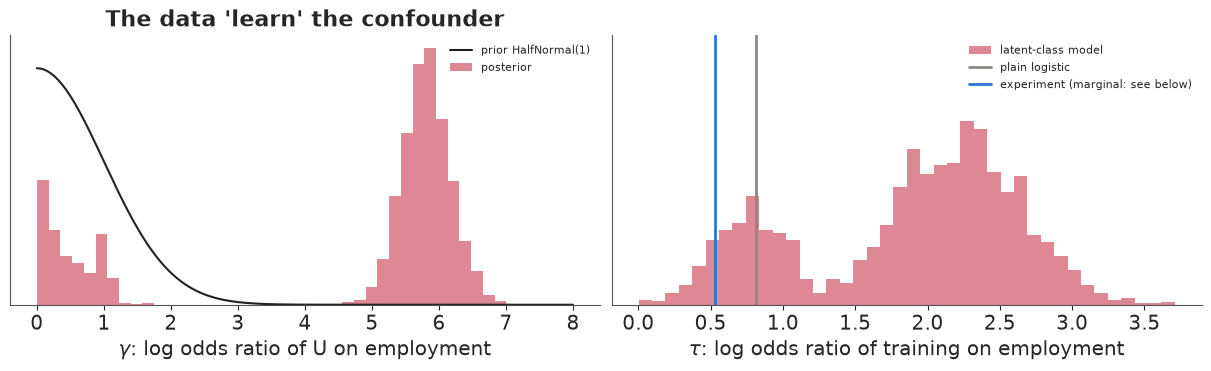

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
g_post = idata_bin.posterior["gamma"].values.ravel()
grid = np.linspace(0, 8, 300)
axes[0].plot(grid, stats.halfnorm.pdf(grid, scale=1.0), color=INK, lw=1.5, label="prior HalfNormal(1)")
axes[0].hist(g_post, bins=40, density=True, color=RED, alpha=0.6, label="posterior")
axes[0].set(xlabel=r"$\gamma$: log odds ratio of U on employment", yticks=[], title="The data 'learn' the confounder")
axes[0].legend(fontsize=8)
axes[1].hist(idata_bin.posterior["tau"].values.ravel(), bins=40, density=True, color=RED, alpha=0.6,
             label="latent-class model")
axes[1].axvline(TAU_LOGIT, color=MUTED, lw=2, label="plain logistic")
axes[1].axvline(EXP_LOR, color=BLUE, lw=2, label="experiment (marginal: see below)")
axes[1].set(xlabel=r"$\tau$: log odds ratio of training on employment", yticks=[])
axes[1].set_ylim(top=1.4 * axes[1].get_ylim()[1])
axes[1].legend(fontsize=8, loc="upper right");

The result is the opposite of a sensitivity analysis. The per-chain means show two solutions.
In this run three chains put the effect of $U$ on employment, $\gamma$, near **5.8**
with an sd of about 0.4, from a prior that puts 95% of its mass below 2: the model is sure that a
hidden binary trait multiplies the odds of working by a factor of several hundred. The trainees
have less of it ($\eta_1 \approx -1.3$), and $\tau$ rises to about **2.2**, against 0.82 for the
plain logistic regression. The fourth chain keeps $\gamma$ below 1 and $\tau$ near the plain
regression. r_hat is about 1.5 only because the chains disagree, and all the divergences come
from that fourth chain; the three in the large-$\gamma$ solution sampled cleanly. Had all four
landed there, nothing would have flagged a confident, wrong answer.

Before reading 2.2 against the experiment's 0.53 we have to put them on one scale. Odds ratios are
**non-collapsible**: adding a strong predictor of the outcome to a logistic model raises the
conditional odds ratio of training even when that predictor is no confounder at all. The
experiment's 0.53 is marginal; the plain regression's 0.82 is conditional on 16 covariates, the
latent-class $\tau$ on $U$ as well. Risk differences on the trainees do collapse, so we compute
them by g-computation: for each posterior draw, average the 185 trainees' predicted employment
with training switched on and off, keeping their covariates and their share of $U$; likewise for
the plain fit. Then we check whether the mixture is absorbing misfit, by comparing predicted
employment with what happened, in bins of the plain model's prediction and by earnings history.

In [21]:
post_b = idata_bin.posterior
Xt = X_std[d_o == 1]
l0_t = post_b["a"].values[..., None] + np.einsum("cdk,nk->cdn", post_b["b"].values, Xt)   # chain, draw, trainee
pi1_t = special.expit(post_b["eta0"].values + post_b["eta1"].values)[..., None]
g_t = post_b["gamma"].values[..., None]


def p_trainees(lin_):
    return (pi1_t * special.expit(lin_ + g_t) + (1 - pi1_t) * special.expit(lin_)).mean(-1)


p1_b, p0_b = p_trainees(l0_t + post_b["tau"].values[..., None]), p_trainees(l0_t)
b_plain = logit_newton(emp_o, Zl)
Zt1, Zt0 = Zl[d_o == 1], Zl[d_o == 1].copy()
Zt0[:, 1] = 0.0
q1, q0 = special.expit(Zt1 @ b_plain).mean(), special.expit(Zt0 @ b_plain).mean()
rows = [{"fit": "experiment (marginal)", "log OR on the model's scale": EXP_LOR, "risk difference": p1_e - p0_e,
         "risk ratio": p1_e / p0_e},
        {"fit": "plain logistic", "log OR on the model's scale": b_plain[1], "risk difference": q1 - q0, "risk ratio": q1 / q0}]
for c in range(post_b.sizes["chain"]):
    rows.append({"fit": f"latent class, chain {c} (gamma {g_t[c].mean():.1f})",
                 "log OR on the model's scale": post_b["tau"].values[c].mean(),
                 "risk difference": (p1_b - p0_b)[c].mean(), "risk ratio": (p1_b / p0_b)[c].mean()})
print("effect of training on the trainees' employment in 1978:")
print(pd.DataFrame(rows).set_index("fit").round(3).to_string())

big = post_b["gamma"].mean("draw").values > 2                                # chains in the large-gamma solution
th = slice(None, None, 10)
l_all = (post_b["a"].values[:, th, None] + np.einsum("cdk,nk->cdn", post_b["b"].values[:, th], X_std)
         + post_b["tau"].values[:, th, None] * d_o)
pi_all = special.expit(post_b["eta0"].values[:, th, None] + post_b["eta1"].values[:, th, None] * d_o)
p_all = pi_all * special.expit(l_all + post_b["gamma"].values[:, th, None]) + (1 - pi_all) * special.expit(l_all)
cal = pd.DataFrame({"observed": emp_o, "plain logistic": special.expit(Zl @ b_plain)})
if big.any():
    cal["latent, large gamma"] = p_all[big].mean(axis=(0, 1))
if (~big).any():
    cal["latent, small gamma"] = p_all[~big].mean(axis=(0, 1))
del l_all, pi_all, p_all
bins = pd.cut(cal["plain logistic"], [0, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0])
print("\nemployment in 1978, observed and predicted, by the plain model's prediction:")
print(cal.groupby(bins, observed=True).mean().assign(men=cal.groupby(bins, observed=True).size()).round(3).to_string())
hist = np.select([d_o == 1, (obs.u74 == 1) & (obs.u75 == 1), (obs.u74 == 1) | (obs.u75 == 1)],
                 ["trainees", "CPS, no earnings 1974-75", "CPS, no earnings in one year"], "CPS, earned both years")
print("\nby group:")
print(cal.groupby(hist).mean().assign(men=cal.groupby(hist).size()).round(3).to_string())
pc = cal.drop(columns="observed").clip(1e-9, 1 - 1e-9)
print("\nlog score of the mean predictions:", (emp_o[:, None] * np.log(pc) + (1 - emp_o[:, None]) * np.log(1 - pc)).sum().round(1).to_dict())

effect of training on the trainees' employment in 1978:
                                   log OR on the model's scale  risk difference  risk ratio
fit                                                                                        
experiment (marginal)                                    0.533            0.111       1.171
plain logistic                                           0.816            0.142       1.231
latent class, chain 0 (gamma 5.8)                        2.226            0.205       1.382
latent class, chain 1 (gamma 5.8)                        2.233            0.205       1.380
latent class, chain 2 (gamma 5.8)                        2.255            0.205       1.382
latent class, chain 3 (gamma 0.5)                        0.744            0.127       1.202

employment in 1978, observed and predicted, by the plain model's prediction:
                observed  plain logistic  latent, large gamma  latent, small gamma   men
plain logistic                           

On a common scale most of the drama goes. The plain logistic regression's 0.82 becomes a risk
difference of about 14 points on the trainees, a risk ratio of 1.23, against the experiment's 11
points and 1.17: part of the gap between 0.82 and 0.53 was the change of scale. The chains in the
large-$\gamma$ solution give about 21 points and a risk ratio of 1.38, so most of the jump from
0.82 to 2.2 was non-collapsibility too. What is left is still a "found" confounder that moved
the answer ten points from the experiment, against three for the plain regression.

The calibration tables show where that strength comes from. The plain logistic regression is off
in a systematic way: where it predicts below 50% the men work less than it says, between 50% and
80% they work more, and CPS men with no earnings in one of the two years are under-predicted by
five points. The large-$\gamma$ solution follows the observed rates closely in those bins and
gains about 48 points of in-sample log score with three more parameters than the plain model,
far more than overfitting could buy; the small-$\gamma$ chain predicts like the plain model. The
data can tell a mixture of two logistic curves from one, so the "confounder" is identified by
the shape of the outcome model, not by anything about confounding. Misfit of a single logistic
regression is absorbed by $U$, and once $U$ exists it is free to differ between the groups.
The lesson is a diagnostic: **in a sensitivity model, the sensitivity parameters should come
back as their priors**. When a latent confounder's parameters move far from their prior, the
model is learning misspecification (Gustafson 2015 discusses when such parameters are learned);
the safe designs are those of F1 and F2, where the likelihood cannot see them.

## G · Evidence that can narrow it

Sensitivity analysis says how fragile an estimate is. Only evidence can say whether the fragility
matters. Two kinds are available here.

### G1 · A placebo outcome

A **negative-control outcome** (Lipsitch, Tchetgen Tchetgen & Cohen 2010) is one the treatment
cannot affect but which shares the outcome's confounding. Earnings in 1975, before training began,
are a natural choice, with 1974 earnings as the lagged control (Heckman & Hotz 1989; Imbens 2015
used this test on these data). If the adjusted comparison of trainees and CPS men gives a non-zero
"effect" on 1975 earnings, something that drives selection is not captured. Inside the experiment
the same test should pass by randomisation.

                                      regression  robust se  weighting  matching
placebo on 1975 earnings                                                        
trainees vs CPS, demographics + 1974     -1135.0      272.0    -1155.0   -1218.0
trainees vs CPS, flexible                -1127.0      280.0    -1360.0   -1370.0
inside the experiment                      224.0      218.0        NaN       NaN


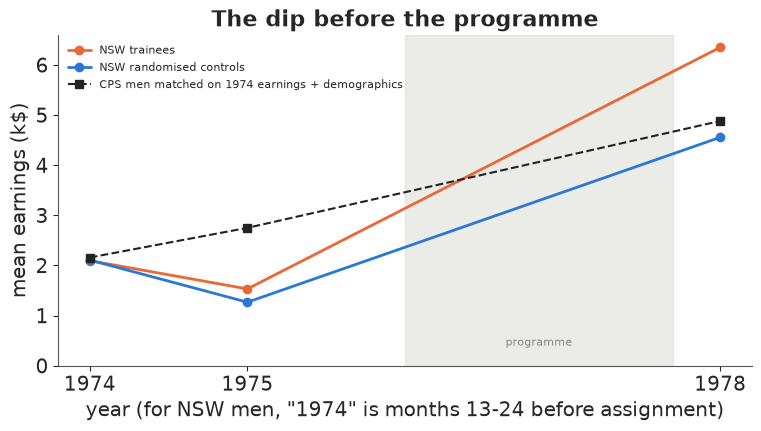

In [22]:
def placebo_X(df, flex=False):
    a_, e_, r74 = df.age.to_numpy(float), df.educ.to_numpy(float), df.re74.to_numpy(float)
    cols = [df[c].to_numpy(float) for c in DEMO] + [r74, df.u74.to_numpy(float)]
    if flex:
        cols += [a_ ** 2 / 100, a_ ** 3 / 1e4, e_ ** 2 / 10, e_ * r74 / 10, r74 ** 2 / 1e5]
    return np.column_stack(cols)


y75 = obs.re75.to_numpy(float)
plac = []
for flex in (False, True):
    Xp = placebo_X(obs, flex)
    e, s, _ = treat_ols(y75, d_o, Xp, hc=True)
    lpp = logit_fit(d_o, Xp)
    tp, cp = nn_match(lpp, d_o)
    plac.append({"placebo on 1975 earnings": "trainees vs CPS, " + ("flexible" if flex else "demographics + 1974"),
                 "regression": e, "robust se": s, "weighting": att_ipw(y75, d_o, lpp), "matching": np.mean(y75[tp] - y75[cp])})
e, s, _ = treat_ols(nsw.re75.to_numpy(float), d_e, placebo_X(nsw), hc=True)
plac.append({"placebo on 1975 earnings": "inside the experiment", "regression": e, "robust se": s})
print(pd.DataFrame(plac).set_index("placebo on 1975 earnings").round(0).to_string())

lp_p = logit_fit(d_o, placebo_X(obs))
tp, cp = nn_match(lp_p, d_o)
yrs = ["re74", "re75", "re78"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for lab, rows_, c, ls in [("NSW trainees", nsw.treat == 1, ORANGE, "-"), ("NSW randomised controls", nsw.treat == 0, BLUE, "-")]:
    ax.plot([1974, 1975, 1978], nsw[rows_][yrs].mean().to_numpy() / 1000, "o" + ls, color=c, lw=2, label=lab)
ax.plot([1974, 1975, 1978], obs.iloc[cp][yrs].mean().to_numpy() / 1000, "s--", color=INK, lw=1.5,
        label="CPS men matched on 1974 earnings + demographics")
ax.axvspan(1976, 1977.7, color=LIGHT, alpha=0.5)
ax.text(1976.85, 0.4, "programme", ha="center", fontsize=8, color=MUTED)
ax.set(xlabel="year (for NSW men, \"1974\" is months 13-24 before assignment)", ylabel="mean earnings (k$)",
       xticks=[1974, 1975, 1978], ylim=(0, None),
       title="The dip before the programme")
ax.legend(fontsize=8);

The placebo **fails**. Adjusted for demographics and 1974 earnings, trainees earned about
**\$1,135 less** in 1975 than comparable CPS men (robust se \$272), and the flexible version,
weighting and matching all say \$1,100-1,400. Inside the experiment the same test gives \$224 (se
\$218), as it should. Yet part B3 showed that the flexible 1978 comparison, which also adjusts for
1975 earnings, is off by only \$40. A failed placebo next to a nearly unbiased estimate is not a
contradiction; it tells us how to read placebo tests.

The figure shows why. Trainees and randomised controls both earned about \$2,100 in 1974, about
\$1,300-1,500 in 1975, and then the controls recovered on their own to \$4,500 by 1978. CPS men
who matched them in 1974 instead rose to about \$2,700 in 1975. Programme eligibility required
recent unemployment, so applicants were men whose earnings had just fallen, the pattern
Ashenfelter (1978) found before training programmes in general. The 1975 shortfall is a temporary
shock that selection worked on, and it largely reverses by 1978 whether or not a man is trained.
So, given 1974 earnings and demographics, 1975 earnings carry more confounding than 1978 earnings
carry once 1975 is also adjusted for: the test measures the dip, not the bias in the real
outcome. (The NSW "1974" column is months 13-24 before assignment, so the first point of each NSW
line sits only roughly at 1974.) A failed placebo should still be reported, as evidence that
something about selection is not captured; a passed one would prove no more, since agreement on
one pre-treatment outcome says nothing of confounders acting on the later one.

### G2 · The within-study comparison

The strongest evidence in this notebook is part B3: the comparison group, with the flexible
adjustment, reproduces the randomised controls' 1978 earnings to within \$40 (se about \$490), a
direct measurement of the bias for this population, outcome and specification. It exists only
because an experiment was run. Elsewhere the nearest substitutes are a small randomised holdout
(E101-E103), a past experiment on a similar population, and placebos, with the limits just seen.

## H · Saying it

Suppose an analyst with only the trainees and the CPS had decided, before seeing the estimate,
that the most plausible hidden confounder is something like the earnings history not fully
captured by two years of data. In this notebook we picked that block after the fact; writing the
range down first is what would make the table below honest. The table leads with that benchmark
and puts the robustness value after it.

In [23]:
bd1, by1 = bench_bounds(*bench_r2["1975 earnings block"], 1)
bd2, by2 = bench_bounds(*bench_r2["1975 earnings block"], 2)
adj1, adj2 = adjusted(EST, SE, DOF, by1, bd1)[0], adjusted(EST, SE, DOF, by2, bd2)[0]
b1, b3 = bench_bayes.iloc[0], bench_bayes.iloc[1]
def money(v):
    v = round(v)
    return f"-${-v:,}" if v < 0 else f"${v:,}"


def in_units(r_d, r_y):
    """A planted confounder of this strength in plain units: how far trainees sit above look-alike
    comparison men in U (sd of U), and what one sd of U is worth in 1978 earnings."""
    U = plant(y_o, d_o, X_f, r_d, r_y, +1, rng=np.random.default_rng(RANDOM_SEED + 3))
    return ols(U, np.column_stack([d_o, X_f]))[0][1], ols(y_o, np.column_stack([d_o, X_f, U]))[0][-1]


def units_text(r_d, r_y):
    gap, per_sd = in_units(r_d, r_y)
    return f"{gap:.2f} sd x {money(per_sd)} per sd = {money(gap * per_sd)} of bias"


adjA = adjusted(EST, SE, DOF, RVA, RVA)[0]
report = pd.DataFrame([
    ("Estimate (regression, flexible covariates)", money(EST), "",
     f"95% CI {money(EST - 1.96 * SE)} to {money(EST + 1.96 * SE)}"),
    ("If a hidden confounder were as strong as the 1975 earnings block", money(adj1), units_text(bd1, by1),
     f"partial R2 {bd1:.2%} with training, {by1:.1%} with earnings; 2x as strong: {money(adj2)}"),
    ("Equal-strength confounder that brings it to zero", money(0), units_text(RV1, RV1),
     f"partial R2 {RV1:.1%} on both sides (the robustness value)"),
    ("... that makes it not significant", money(adjA), units_text(RVA, RVA), f"partial R2 {RVA:.2%} on both sides"),
    ("Bayesian interval, confounder up to 1x that block", f"{money(b1['5%'] * 1000)} to {money(b1['95%'] * 1000)}", "",
     f"P(effect > 0) {b1['P(tau > 0)']:.2f}"),
    ("Bayesian interval, up to 3x", f"{money(b3['5%'] * 1000)} to {money(b3['95%'] * 1000)}", "",
     f"P(effect > 0) {b3['P(tau > 0)']:.2f}"),
    ("E-value, employment in 1978", f"{evt.loc['flex', 'E-value']:.2f}", "", "interval includes no effect (E-value 1)"),
    ("Placebo: 'effect' on 1975 earnings", money(plac[0]['regression']), "", "fails: pre-programme earnings dip"),
], columns=["question", "estimate", "U gap x worth per sd = bias", "note"]).set_index("question")
print(report.to_string())
gap_rv, per_rv = in_units(RV1, RV1)
print(f"\nA hidden factor as strong as the 1975 earnings variables we already adjust for would cut the {money(EST)} "
      f"to about {money(adj1)}, and one twice as strong would reverse it. Removing the estimate entirely would take a "
      f"factor on which trainees sit {gap_rv:.1f} sd above look-alike comparison men, each sd worth about "
      f"{money(per_rv)} in 1978 earnings (partial R2 {RV1:.1%} on both sides).")
# the planted-confounder demonstration at the two points of the table: estimate with U and balance after matching
for lab, (r_d, r_y) in [("the robustness value", (RV1, RV1)), ("1x the 1975 block", (bd1, by1))]:
    U = plant(y_o, d_o, X_f, r_d, r_y, +1, rng=np.random.default_rng(RANDOM_SEED + 3))
    e_u = treat_ols(y_o, d_o, np.column_stack([X_f, U]))[0]
    s_pool = np.sqrt((U[d_o == 1].var() + U[d_o == 0].var()) / 2)
    print(f"planted U at {lab}: estimate with U {money(e_u)}; SMD of U after matching "
          f"{(U[ti].mean() - U[ci].mean()) / s_pool:.2f}, largest measured |SMD| still {bal['after matching'].drop('planted U (3%)').abs().max():.2f}")

                                                                         estimate               U gap x worth per sd = bias                                                                     note
question                                                                                                                                                                                            
Estimate (regression, flexible covariates)                                 $1,572                                                                                              95% CI $480 to $2,664
If a hidden confounder were as strong as the 1975 earnings block             $409  0.54 sd x $2,161 per sd = $1,163 of bias  partial R2 0.28% with training, 9.6% with earnings; 2x as strong: -$757
Equal-strength confounder that brings it to zero                               $0  1.50 sd x $1,045 per sd = $1,572 of bias                     partial R2 2.2% on both sides (the robustness value)
... that makes 

The table answers, in order, what the estimate is, what a plausible hidden confounder would do
to it, how much it would take to remove it, and what evidence there is. Strengths are given in
units a reader can picture, because a bare "2.2%" sounds negligible when it is not: how far
trainees sit above look-alike comparison men on $U$, times what one sd of $U$ is worth in
earnings, which is the bias: 1.5 sd at \$1,045 per sd is the whole
\$1,572, and 0.54 sd at \$2,161 per sd is the \$1,163 that takes it to \$409.

Why does a confounder "only" as strong as the block do nearly as much damage as the robustness
value? The robustness value is the equal-strength point on the contour of figure 3, 8 times the
block on training but 0.23 times on earnings, and a realistic confounder is rarely
equal-strength: the block is weak on training and strong on earnings. So show a funder the
benchmark row and the contour plot, not "8 times the block". The planted confounders printed last
move the estimate as the table says, differ by 1.65 and 0.66 sd after matching, and leave the
measured covariates' balance untouched.

The verdict is not flattering: the \$1,572 is significant and close to the truth, but a plausible
confounder would cut it to \$400, and the placebo test fails. A funder should conclude that the
observational data point to a positive effect that a plausible confounder could largely erase,
and that the decision should wait for, or be staged around, a randomised test (a holdout, as in
E101-E103). Here the experiment exists, and it agrees with the estimate: a sensitivity analysis
says not that an estimate is wrong, only how much of its force rests on nothing being missing.

The sentence printed below the table is the **tipping point**, the habit this notebook is meant to
leave: answer "how strong would a hidden confounder have to be, compared with what we measured, to
change the decision?" before anyone asks. Three demonstrations from this notebook can be repeated
on any data. Remove your strongest measured block of covariates and show how far the estimate
moves (B2). Plant synthetic confounders on your own rows at the robustness value and at 1x the
strongest benchmark, and show the estimate with each beside the balance table, which does not
change (C2, C3 and the lines above). Show the contour plot with the benchmarks (D2). Then write
the plausible range of confounder strength down **before** looking at the estimate, naming the
measured variable it most resembles, and report both directions: here a confounder of 0.3% pushing
the estimate down was all that separated it from the experiment.

In [24]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 116 s


## Summary

- **Hiding a measured confounder flips the sign.** Against the experiment's \$1,794, NSW trainees
  compared with 15,992 CPS men give -\$8,498 raw and \$1,572 with a flexible specification
  including 1974-75 earnings; without the earnings history it says -\$3,690 with t = -5.2. The
  randomised controls against the CPS measure the bias directly: \$4,264 with demographics, \$40
  with the flexible set; one programme and one comparison sample.
- **Omitted-variable bias is exact algebra, and small confounders do big things.** Confounders
  planted on the real rows moved the estimate exactly as the partial-$R^2$ formula predicts: 3% of
  leftover variance on both sides reverses it to -\$586 or hides a real \$1,850 behind zero, and
  after matching such a confounder was off by 1.87 sd while every measured covariate was within
  0.18. The formula is exact for the regression only, not for weighting or matching.
- **The robustness value is small, and benchmarks decide whether that matters.** $RV = 2.2\%$
  (0.67% for significance), with the code checked against the Darfur example. A confounder as
  strong as the 1975 earnings block cuts the estimate to \$409; single correlated covariates
  understate, and demographic benchmarks allowed 4.5% of outcome variance where the
  hidden earnings block had 41%. We chose our benchmark after seeing the data, so it argues
  rather than proves.
- **E-values and Rosenbaum's $\Gamma$ measure strength, not truth.** A wrong-signed employment
  risk ratio (0.89) has an E-value of 1.48, close to the right answer's 1.61. The matched design
  built first was not significant (p = 0.38); the experiment itself, read as pairs, loses
  significance at $\Gamma = 1.13$, because 185 noisy pairs are fragile whatever their design.
- **Bayesian sensitivity models return their priors, and should.** The latent-confounder model's
  sensitivity parameters came back as their priors; benchmark priors gave \$360-2,590 (up to 1x
  the 1975 block) and -\$600 to \$3,690 (up to 3x), both covering the experiment, though uniform
  priors keep most of the bias near zero and so understate the worst case. A binary latent
  confounder "learned" a log-odds effect near 5.8 in three of four chains in this run, and put the
  trainees' gain in employment at about 21 points against 11 in the experiment: misspecification,
  not confounding.
- **A placebo test can fail while the estimate is right.** Trainees earned \$1,135 (se \$272)
  less in 1975 than comparable CPS men, the pre-programme dip, while the 1978 estimate was off by
  \$40: a negative control is only as good as the argument that it shares the outcome's
  confounding.

## Try it yourself

1. **Choose a benchmark first, then test it.** Before running anything, pick a different benchmark
   for the plausible confounder (for example "as strong as schooling and the no-degree indicator
   together") and write down the range of $k$ you find plausible. Then compute the adjusted
   estimates and the F2 intervals. Do they cover the experiment? How would you have argued for
   your choice to a sceptic?
2. **Sensitivity of a different estimator.** Apply the planted confounders of part C to the
   odds-weighted and matched estimates instead of the regression. The formula no longer holds
   exactly: how far off is it, and does the 3% confounder still reverse the weighted estimate?
3. **Make the latent-class model behave.** In F3, replace the linear logit with a more flexible
   one (splines in age and the earnings variables, or a zero-earnings hurdle) and refit. Does
   $\gamma$ fall back toward its prior as the outcome model improves? If it does, you have shown
   that the "confounder" was absorbing misfit.